In [2]:
import pandas as pd

df = pd.read_parquet('C:/Users/NT751/Desktop/천영진/리스테리아ML/data/listeria_body.parquet')

In [3]:
import pandas as pd

# 1. 엑셀 스키마 로드
schema_path = r'C:\Users\NT751\Desktop\천영진\테이블명세서(모델팀)\테이블정의서.xlsx'
schema = pd.read_excel(schema_path, sheet_name='ready_data', header=0)

# 필요한 컬럼 추출 및 결측치 제거
schema = schema[['컬럼', '설명']].dropna(subset=['컬럼'])

# 텍스트 양끝 공백 제거 (매칭률 향상)
schema['컬럼'] = schema['컬럼'].astype(str).str.strip()
schema['설명'] = schema['설명'].astype(str).str.strip()

# 엑셀 내 중복 컬럼명이 있을 경우 첫 번째 설명만 유지 (행 증폭 방지)
schema = schema.drop_duplicates(subset=['컬럼'], keep='first')

# 2. 데이터프레임 컬럼 추출 및 전처리
_df_columns = pd.DataFrame({'df_컬럼명': [str(col).strip() for col in df.columns]})

# 3. 매핑 수행
df_칼럼명 = _df_columns.merge(
    schema,
    left_on='df_컬럼명',
    right_on='컬럼',
    how='left'
).drop(columns=['컬럼']).rename(columns={'설명': '명세서_설명'})

# 4. 매칭 여부 플래그 생성
df_칼럼명['매칭여부'] = df_칼럼명['명세서_설명'].notna()

# 5. 결과 출력
display(df_칼럼명)

unmatched_cols = df_칼럼명.loc[~df_칼럼명['매칭여부'], 'df_컬럼명'].tolist()
print(f"총 컬럼 수: {len(df_칼럼명)}개 / 매칭 성공: {df_칼럼명['매칭여부'].sum()}개")
print('명세서 미매칭 컬럼:', unmatched_cols)

,df_컬럼명,명세서_설명,매칭여부
0,lims_data_key,PK. 소스별 조합 키,True
1,hazard_label,위해요소명 (10종),True
2,judge_result,목표변수. 검출 / 불검출. 병합 시 '하나라도 검출이면 검출',True
3,src_route,NaN,False
4,data_source,NaN,False
5,expr_iem_nm,시험항목명(대표행 기준). 농관원 행은 조사 구분(anals_se)이 들어간다,True
6,result_value,검출값(원본 문자열). 정량·정성이 섞여 있어 물질 간 직접 비교 불가,True
7,result_value_num,NaN,False
8,judge_stdr,NaN,False
9,judge_stdr_num,NaN,False


총 컬럼 수: 23개 / 매칭 성공: 18개
명세서 미매칭 컬럼: ['src_route', 'data_source', 'result_value_num', 'judge_stdr', 'judge_stdr_num']


# 1. df 전체 컬럼 요약: 컬럼명 / 데이터타입 / 결측 수 / 결측 비율 / 유니크 값 수 / 최빈값 5개


In [4]:
_n = len(df)
_rows = []
for col in df.columns:
    s = df[col]
    top5 = s.value_counts(dropna=True).head(5)
    _rows.append({
        '컬럼명': col,
        '데이터타입': str(s.dtype),
        '결측 수': int(s.isna().sum()),
        '결측 비율(%)': round(s.isna().mean() * 100, 2),
        '유니크 값 수': int(s.nunique(dropna=True)),
        '최빈값 5개': [f'{v} ({c:,})' for v, c in top5.items()],
    })

df_컬럼요약 = pd.DataFrame(_rows)
# 명세서 설명도 함께 붙이기
df_컬럼요약 = df_컬럼요약.merge(
    df_칼럼명[['df_컬럼명', '명세서_설명']],
    left_on='컬럼명', right_on='df_컬럼명', how='left'
).drop(columns='df_컬럼명')

print(f'총 {_n:,} rows × {df.shape[1]} columns')
display(df_컬럼요약)

총 676,537 rows × 23 columns


,컬럼명,데이터타입,결측 수,결측 비율(%),유니크 값 수,최빈값 5개,명세서_설명
0,lims_data_key,string,0,0.00,676537,"[O000001_160100103_5_4 (1), O000001_160100300_...",PK. 소스별 조합 키
1,hazard_label,category,0,0.00,1,"[리스테리아 (676,537)]",위해요소명 (10종)
2,judge_result,category,0,0.00,2,"[불검출 (674,568), 검출 (1,969)]",목표변수. 검출 / 불검출. 병합 시 '하나라도 검출이면 검출'
3,src_route,category,0,0.00,2,"[domestic (628,895), overseas (47,642)]",NaN
4,data_source,category,0,0.00,1,"[식약처 (676,537)]",NaN
5,expr_iem_nm,category,0,0.00,4,"[리스테리아모노사이토제네스 (660,130), 리스테리아 모노사이토제네스 (15,7...",시험항목명(대표행 기준). 농관원 행은 조사 구분(anals_se)이 들어간다
6,result_value,string,0,0.00,100,"[음성 (376,777), 음성,음성,음성,음성,음성 (281,865), 불검출 (...",검출값(원본 문자열). 정량·정성이 섞여 있어 물질 간 직접 비교 불가
7,result_value_num,float32,672760,99.44,2,"[0.0 (3,775), 2.0 (2)]",NaN
8,judge_stdr,string,669264,98.92,17,"[n=5,c=0,m=0/25g (4,692), n=5, c=0, m=0/25g (1...",NaN
9,judge_stdr_num,float32,676469,99.99,5,"[100.0 (62), 20.0 (3), 25.0 (1), 1000.0 (1), 0...",NaN


In [5]:
judge_counts = (
    df['judge_result']
    .value_counts(dropna=False)
    .rename_axis('judge_result')
    .reset_index(name='count')
)

judge_counts['ratio_pct'] = (judge_counts['count'] / judge_counts['count'].sum() * 100).round(3)
display(judge_counts)

,judge_result,count,ratio_pct
0,불검출,674568,99.709
1,검출,1969,0.291


## 홍석민 선생님께 받은 최초데이터 : 양성률 0.291, 총 676,537 rows × 23 columns

# 2. 검출률0% 품목 삭제

In [6]:
# train_prdlst_nm 범주별 '검출' 비율 계산
cat_rate = (
    df.loc[df['train_prdlst_nm'].notna()]
    .groupby('train_prdlst_nm', dropna=True)['judge_result']
    .apply(lambda s: (s == '검출').mean())
    .rename('검출비율')
    .sort_values(ascending=False)
)

# '검출' 비율이 0%인 범주만 삭제
valid_cats = cat_rate[cat_rate > 0].index
removed_cats = list(cat_rate[cat_rate == 0].index)

df_filtered = df[df['train_prdlst_nm'].isin(valid_cats)].copy()

print(f"원본 범주 수: {df['train_prdlst_nm'].nunique(dropna=True):,}")
print(f"삭제된 0% 범주 수: {len(removed_cats):,}")
if removed_cats:
    print("삭제된 범주:", removed_cats)
print(f"남은 범주 수: {df_filtered['train_prdlst_nm'].nunique(dropna=True):,}")
print(f"남은 행 수: {len(df_filtered):,}")

# 결과 확인용
display(cat_rate.reset_index().head(20))

원본 범주 수: 53
삭제된 0% 범주 수: 38
삭제된 범주: ['개별인정원료', '가공식품(전부개정)', '과일류', '곡류', '기타', '기능성 원료', '면류', '두부류 또는 묵류', '두류', '동물성가공식품류', '농산물 종자류', '당류', '기타제조가공식품류(자가규격)', '기타첨가물', '식용유지류', '빙과류', '알가공품류', '식품첨가물', '영양성분', '서류', '수산가공', '벌꿀 및 화분가공품류', '잼류', '장류', '인삼.홍삼제품류', '접객용 음용수', '조류', '조리식품 등', '조미식품', '절임류 또는 조림류', '주류', '채소류', '코코아가공품류 또는 초콜릿류', '특수영양식품', '특수의료용도식품', '혼합제제류', '환경검체', '환경오염도조사용']
남은 범주 수: 15
남은 행 수: 600,040


,train_prdlst_nm,검출비율
0,버섯류,0.130435
1,기타식물류,0.046512
2,"정액,수정란,종란",0.022338
3,축산물,0.016176
4,수산가공식품류,0.005900
5,수산물,0.005429
6,견과 종실류,0.003425
7,식육가공품 및 포장육,0.003197
8,기타기준규격외,0.002711
9,즉석식품류,0.001274


## 삭제된 범주 별, 연도 별 행 수

In [7]:
# 삭제된(검출 0%인) 범주별, 연도별 행 수
# - train_prdlst_nm == '검출 0%' 범주만 집계
# - 연도는 mnfctur_de 기준

# 안전하게 제거된 범주 목록 재생성 (이미 있으면 그대로 사용)
if 'removed_cats' not in globals():
    valid_cats = (
        df.loc[df['train_prdlst_nm'].notna()]
        .groupby('train_prdlst_nm', dropna=True)['judge_result']
        .apply(lambda s: (s == '검출').mean())
        .rename('검출비율')
        .sort_values(ascending=False)
    )
    valid_cats = valid_cats[valid_cats > 0].index
    removed_cats = list(
        df.loc[df['train_prdlst_nm'].notna(), 'train_prdlst_nm']
        .dropna()
        .unique()
    )
    removed_cats = [c for c in removed_cats if c not in valid_cats]

removed_cats = [str(c) for c in removed_cats if pd.notna(c)]
print(f"삭제 범주 수: {len(removed_cats)}")
print("삭제 범주:", removed_cats)

# 삭제 범주만 필터
removed_df = df.loc[
    df['train_prdlst_nm'].isin(removed_cats)
].copy()

# 기준일 연도 계산
removed_df['year'] = pd.to_datetime(removed_df['mnfctur_de'], errors='coerce').dt.year

# 범주별 · 연도별 행 수
removed_year_counts = (
    removed_df.groupby(['train_prdlst_nm', 'year'], dropna=True)
    .size()
    .rename('행수')
    .reset_index()
    .sort_values(['train_prdlst_nm', 'year'])
)

# 범주별 총 행 수
removed_cat_total = (
    removed_year_counts.groupby('train_prdlst_nm', as_index=False)['행수']
    .sum()
    .rename(columns={'행수': '총행수'})
    .sort_values('총행수', ascending=False)
)

# 피벗으로 보기
removed_year_pivot = (
    removed_year_counts
    .pivot_table(index='train_prdlst_nm', columns='year', values='행수', aggfunc='sum', fill_value=0)
    .sort_index()
)

display(removed_cat_total)
display(removed_year_pivot)

삭제 범주 수: 38
삭제 범주: ['개별인정원료', '가공식품(전부개정)', '과일류', '곡류', '기타', '기능성 원료', '면류', '두부류 또는 묵류', '두류', '동물성가공식품류', '농산물 종자류', '당류', '기타제조가공식품류(자가규격)', '기타첨가물', '식용유지류', '빙과류', '알가공품류', '식품첨가물', '영양성분', '서류', '수산가공', '벌꿀 및 화분가공품류', '잼류', '장류', '인삼.홍삼제품류', '접객용 음용수', '조류', '조리식품 등', '조미식품', '절임류 또는 조림류', '주류', '채소류', '코코아가공품류 또는 초콜릿류', '특수영양식품', '특수의료용도식품', '혼합제제류', '환경검체', '환경오염도조사용']


,train_prdlst_nm,총행수
20,알가공품류,29392
15,빙과류,22206
28,조리식품 등,9590
29,조미식품,4165
25,절임류 또는 조림류,2804
33,특수영양식품,2140
31,채소류,904
32,코코아가공품류 또는 초콜릿류,735
3,과일류,702
12,두부류 또는 묵류,489


year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
train_prdlst_nm,,,,,,,,,,,,
가공식품(전부개정),0,0,0,3,0,0,0,0,0,0,0,0
개별인정원료,0,0,0,0,0,0,0,0,3,59,82,19
곡류,0,0,3,0,0,44,1,0,0,2,2,0
과일류,0,0,8,25,494,2,2,102,0,2,67,0
기능성 원료,0,0,6,16,25,12,37,53,31,24,37,30
기타,0,6,132,1,26,0,1,0,0,0,2,2
기타제조가공식품류(자가규격),0,0,0,0,7,0,0,54,29,106,94,52
기타첨가물,0,0,0,1,0,0,0,0,0,0,0,0
농산물 종자류,0,0,0,0,1,0,0,0,4,1,2,0


In [8]:
df_filtered

,lims_data_key,hazard_label,judge_result,src_route,data_source,expr_iem_nm,result_value,result_value_num,judge_stdr,judge_stdr_num,...,train_prdlst_nm,prduct_nm,mnfctur_cmpny_nm,mnfctur_de,date_basis,addr,addr_source,legal_dong_code,lat,lon
0,O000001_160100103_5_4,리스테리아,불검출,domestic,식약처,리스테리아모노사이토제네스,0,0.0,<NA>,NaN,...,기타기준규격외,"화이트초콜릿 65℃, 30min",(주)쵸코하우스,2016-03-11,의뢰일,"경기도 성남시 중원구 둔촌대로 560(상대원동, 벽산테크노피아911,912,906,...",제조사소재지,4113310500,37.433239,127.164383
1,O000001_160100300_4_4,리스테리아,불검출,domestic,식약처,리스테리아모노사이토제네스,음성,NaN,<NA>,NaN,...,기타기준규격외,열무(세척전),(주)해마루,2016-03-22,의뢰일,"경기도 평택시 안중읍 성해2길 63-66 (학현리, 1, 2층)",제조사소재지,4122025300,36.986122,126.931168
2,O000033_170101151_1_5,리스테리아,불검출,domestic,식약처,리스테리아모노사이토제네스,음성,NaN,<NA>,NaN,...,"정액,수정란,종란","볶음-해물,야채(21일째)",<NA>,2017-02-22,제조일,전라북도 고창군 부안면 복분자로 434-36,업소주소,5279043000,35.514168,126.674095
3,O000027_170101235_2_7,리스테리아,불검출,domestic,식약처,리스테리아모노사이토제네스,음성,NaN,<NA>,NaN,...,기타기준규격외,크런치킹샌드(외포장),<NA>,2017-01-20,제조일,광주광역시 북구 하서로 222(양산동),업소주소,2917012800,35.209167,126.879715
4,1471142_170100097_1_1092137,리스테리아,불검출,domestic,식약처,리스테리아모노사이토제네스,음성,NaN,<NA>,NaN,...,축산물,생고기2(삼정),<NA>,2017-03-07,제조일,전라북도 정읍시 정신로 22-12 (하북동),제조사소재지,5218012100,35.595753,126.869698
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
676530,O000086_170100974_2_5,리스테리아,불검출,domestic,식약처,리스테리아모노사이토제네스,음성,NaN,<NA>,NaN,...,기타식품류,샌드위치,<NA>,2017-04-24,제조일,충청남도 천안시 동남구 통정3로 77 (천안하나리움아인스파크 401동 1층 102호...,업소주소,4413111600,36.785915,127.122482
676531,O000142_190100001_1_3847290,리스테리아,불검출,domestic,식약처,리스테리아모노사이토제네스,"음성,음성,음성,음성,음성",NaN,<NA>,NaN,...,식육가공품 및 포장육,불고기맛 소시지,(주)미소담은,2019-02-18,제조일,경상남도 김해시 주촌면 서부로1295번길 81,제조사소재지,4825032000,35.232342,128.841431
676532,1471124_170704332_1_11,리스테리아,불검출,overseas,식약처,리스테리아 모노사이토제네스,"음성,음성,음성,음성,음성",NaN,<NA>,NaN,...,유가공품류,반경성치즈,<NA>,2017-07-19,선적일,5331 GREAT OCEAN ROAD ALLANSFORD VIC 3277,해외제조업소,NaN,-38.395367,142.627716
676535,O000031_170700207_1_5,리스테리아,불검출,domestic,식약처,리스테리아모노사이토제네스,"음성,음성,음성,음성,음성",NaN,<NA>,NaN,...,유가공품류,SRC딸기아이스크림,<NA>,2017-03-29,제조일,충청북도 음성군 삼성면 덕호로94번길 5,인허가대장,4377035000,37.018387,127.495041


    train_prdlst_nm     행수
0             알가공품류  29392
1               빙과류  22206
2            조리식품 등   9590
3              조미식품   4165
4        절임류 또는 조림류   2804
5            특수영양식품   2140
6               채소류    904
7   코코아가공품류 또는 초콜릿류    735
8               과일류    702
9         두부류 또는 묵류    489
10               장류    430
11               면류    411
12            식용유지류    369
13  기타제조가공식품류(자가규격)    342
14               당류    296
15           기능성 원료    271
16         동물성가공식품류    189
17               기타    170
18           개별인정원료    163
19               잼류    148
20         특수의료용도식품     82
21               주류     74
22            식품첨가물     70
23            혼합제제류     68
24      벌꿀 및 화분가공품류     56
25               곡류     52
26          접객용 음용수     50
27             수산가공     40
28             환경검체     35
29         환경오염도조사용     14
30             영양성분     12
31               두류      8
32          농산물 종자류      8
33               서류      4
34         인삼.홍삼제품류      3
35       가공식품(전부개정)      3
3

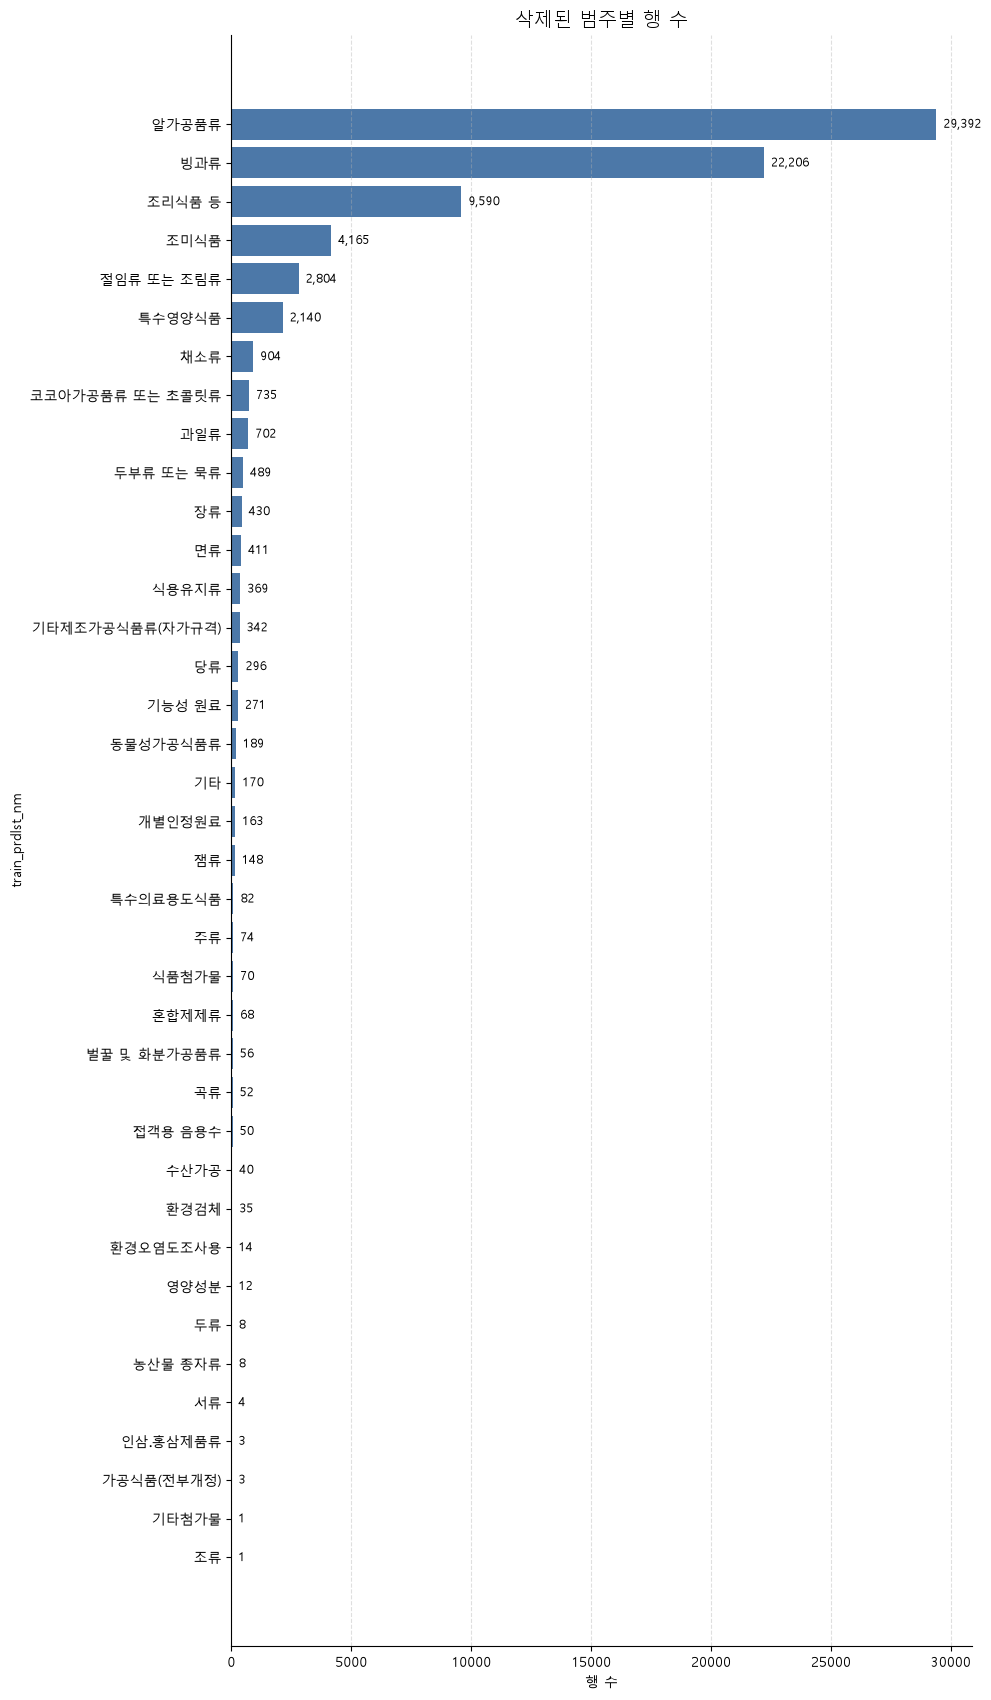

In [31]:
import matplotlib.pyplot as plt

# 삭제된 범주 목록이 아직 없으면 재계산
if 'removed_cats' not in globals():
    valid_cats = (
        df.loc[df['train_prdlst_nm'].notna()]
        .groupby('train_prdlst_nm', dropna=True)['judge_result']
        .apply(lambda s: (s == '검출').mean())
        .rename('검출비율')
        .sort_values(ascending=False)
    )
    valid_cats = valid_cats[valid_cats > 0].index
    removed_cats = [
        c for c in df.loc[df['train_prdlst_nm'].notna(), 'train_prdlst_nm']
        .dropna()
        .unique()
        if c not in valid_cats
    ]

removed_df = df.loc[df['train_prdlst_nm'].isin(removed_cats)].copy()

# 삭제된 범주별 행 수 집계
cat_counts = (
    removed_df['train_prdlst_nm']
    .astype(str)
    .value_counts()
    .sort_values(ascending=False)
    .rename_axis('train_prdlst_nm')
    .reset_index(name='행수')
)

print(cat_counts)

# 시각화
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

fig, ax = plt.subplots(figsize=(10, max(4, len(cat_counts) * 0.45)))

bars = ax.barh(cat_counts['train_prdlst_nm'], cat_counts['행수'], color='#4C78A8')
ax.invert_yaxis()
ax.set_title('삭제된 범주별 행 수', fontsize=14)
ax.set_xlabel('행 수')
ax.set_ylabel('train_prdlst_nm')
ax.xaxis.grid(True, linestyle='--', alpha=0.4)
ax.spines[['top', 'right']].set_visible(False)

# 값 라벨
max_val = cat_counts['행수'].max()
for bar, val in zip(bars, cat_counts['행수']):
    ax.text(val + max_val * 0.01, bar.get_y() + bar.get_height() / 2, f'{val:,}', va='center', fontsize=9)

plt.tight_layout()
plt.show()

# 3. df_filtered 전체 컬럼 요약: 컬럼명 / 데이터타입 / 결측 수 / 결측 비율 / 유니크 값 수 / 최빈값 5개

In [10]:
_n = len(df_filtered)
_rows = []
for col in df_filtered.columns:
    s = df_filtered[col]
    top5 = s.value_counts(dropna=True).head(5)
    _rows.append({
        '컬럼명': col,
        '데이터타입': str(s.dtype),
        '결측 수': int(s.isna().sum()),
        '결측 비율(%)': round(s.isna().mean() * 100, 2),
        '유니크 값 수': int(s.nunique(dropna=True)),
        '최빈값 5개': [f'{v} ({c:,})' for v, c in top5.items()],
    })

df_컬럼요약 = pd.DataFrame(_rows)
# 명세서 설명도 함께 붙이기
df_컬럼요약 = df_컬럼요약.merge(
    df_칼럼명[['df_컬럼명', '명세서_설명']],
    left_on='컬럼명', right_on='df_컬럼명', how='left'
).drop(columns='df_컬럼명')

print(f'총 {_n:,} rows × {df.shape[1]} columns')
display(df_컬럼요약)

총 600,040 rows × 23 columns


,컬럼명,데이터타입,결측 수,결측 비율(%),유니크 값 수,최빈값 5개,명세서_설명
0,lims_data_key,string,0,0.00,600040,"[O000001_160100103_5_4 (1), O000001_160100300_...",PK. 소스별 조합 키
1,hazard_label,category,0,0.00,1,"[리스테리아 (600,040)]",위해요소명 (10종)
2,judge_result,category,0,0.00,2,"[불검출 (598,071), 검출 (1,969)]",목표변수. 검출 / 불검출. 병합 시 '하나라도 검출이면 검출'
3,src_route,category,0,0.00,2,"[domestic (556,266), overseas (43,774)]",NaN
4,data_source,category,0,0.00,1,"[식약처 (600,040)]",NaN
5,expr_iem_nm,category,0,0.00,4,"[리스테리아모노사이토제네스 (584,658), 리스테리아 모노사이토제네스 (14,7...",시험항목명(대표행 기준). 농관원 행은 조사 구분(anals_se)이 들어간다
6,result_value,string,0,0.00,97,"[음성 (355,546), 음성,음성,음성,음성,음성 (229,739), 불검출 (...",검출값(원본 문자열). 정량·정성이 섞여 있어 물질 간 직접 비교 불가
7,result_value_num,float32,596627,99.43,2,"[0.0 (3,411), 2.0 (2)]",NaN
8,judge_stdr,string,593265,98.87,16,"[n=5,c=0,m=0/25g (4,609), n=5, c=0, m=0/25g (1...",NaN
9,judge_stdr_num,float32,599973,99.99,5,"[100.0 (62), 20.0 (2), 25.0 (1), 1000.0 (1), 0...",NaN


# 4. 품목명 별 검측률 확인

## (검출 값이 많은 순부터)

In [11]:
# train_prdlst_nm별 행 수, 검출/불검출 건수, 검출률(%)  — 0% 범주 삭제본(df_filtered) 기준, 검출 건수 많은 순
pd.set_option('display.max_colwidth', 200)

_nm = df_filtered['train_prdlst_nm'].cat.remove_unused_categories()
ct = pd.crosstab(_nm, df_filtered['judge_result'], dropna=False)
summary = ct.assign(행수=ct.sum(axis=1))
summary['검출비율(%)'] = (summary['검출'] / summary['행수'] * 100).round(3)
summary = summary.sort_values(['검출', '행수'], ascending=False).reset_index()
summary.columns.name = None

display(summary)
print(f"전체 train_prdlst_nm 고유값 수: {summary.shape[0]:,}")


,train_prdlst_nm,검출,불검출,행수,검출비율(%)
0,기타기준규격외,791,291022,291813,0.271
1,"정액,수정란,종란",640,28011,28651,2.234
2,식육가공품 및 포장육,323,100722,101045,0.320
3,수산물,46,8427,8473,0.543
4,즉석식품류,45,35277,35322,0.127
5,유가공품류,40,106982,107022,0.037
6,수산가공식품류,29,4886,4915,0.590
7,축산물,28,1703,1731,1.618
8,버섯류,12,80,92,13.043
9,기타식품류,9,7375,7384,0.122


전체 train_prdlst_nm 고유값 수: 15


In [12]:
target_cats = ["기타기준규격외", "정액,수정란,종란", "식육가공품 및 포장육"]

pos_df = df_filtered[df_filtered["judge_result"] == "검출"].copy()
pos_total = len(pos_df)

subset = pos_df[pos_df["train_prdlst_nm"].isin(target_cats)].copy()
subset_total = len(subset)

ratio_pct = (subset_total / pos_total * 100) if pos_total else 0.0

print(f"전체 검출 건수: {pos_total:,}건")
print(f"대상 품목 검출 건수: {subset_total:,}건")
print(f"비율: {ratio_pct:.3f}%")

# 품목별 구성
cat_breakdown = (
    subset["train_prdlst_nm"]
    .value_counts()
    .reindex(target_cats, fill_value=0)
    .rename("검출_건수")
)

display(cat_breakdown)
display(pd.DataFrame({
    "지표": ["전체_검출_건수", "대상_품목_검출_건수", "대상_품목_비율(%)"],
    "값": [pos_total, subset_total, round(ratio_pct, 3)]
}))

전체 검출 건수: 1,969건
대상 품목 검출 건수: 1,754건
비율: 89.081%


train_prdlst_nm
기타기준규격외        791
정액,수정란,종란      640
식육가공품 및 포장육    323
Name: 검출_건수, dtype: int64

,지표,값
0,전체_검출_건수,1969.000
1,대상_품목_검출_건수,1754.000
2,대상_품목_비율(%),89.081


### '식육가공품 및 포장육','정액,수정란,종란','기타기준규격외' 값에서 거의 다 나옴

#### 전체 검출 건수: 1,969건
#### 위 3개 품목에서 검출 건수: 1,754건
#### 비율: 89.081%

### 위 3개 품목에는 무슨 제품들이 있을까?

In [13]:
# train_prdlst_nm 기준으로 각 카테고리의 검출 행만 추출해 prduct_nm 빈도 계산
기타기준규격외_검출제품명 = (
    df_filtered.loc[
        (df_filtered["train_prdlst_nm"] == "기타기준규격외") &
        (df_filtered["judge_result"] == "검출"),
        "prduct_nm"
    ]
    .value_counts()
    .rename_axis("prduct_nm")
    .reset_index(name="검출건수")
    .sort_values("검출건수", ascending=False)
)

정액수정란종란_검출제품명 = (
    df_filtered.loc[
        (df_filtered["train_prdlst_nm"] == "정액,수정란,종란") &
        (df_filtered["judge_result"] == "검출"),
        "prduct_nm"
    ]
    .value_counts()
    .rename_axis("prduct_nm")
    .reset_index(name="검출건수")
    .sort_values("검출건수", ascending=False)
)

식육가공품및포장육_검출제품명 = (
    df_filtered.loc[
        (df_filtered["train_prdlst_nm"] == "식육가공품 및 포장육") &
        (df_filtered["judge_result"] == "검출"),
        "prduct_nm"
    ]
    .value_counts()
    .rename_axis("prduct_nm")
    .reset_index(name="검출건수")
    .sort_values("검출건수", ascending=False)
)

print("=== 기타기준규격외 ===")
display(기타기준규격외_검출제품명)

print("=== 정액,수정란,종란 ===")
display(정액수정란종란_검출제품명)

print("=== 식육가공품 및 포장육 ===")
display(식육가공품및포장육_검출제품명)

=== 기타기준규격외 ===


,prduct_nm,검출건수
0,광어회,10
1,연어회,9
2,연어필렛,6
3,포장육 완제품,5
4,팽이버섯,4
...,...,...
701,순살닭정육,1
702,동원 스페인 등갈비,1
703,구성품1(완제품),1
704,통안심치킨 유탕가열 전,1


=== 정액,수정란,종란 ===


,prduct_nm,검출건수
0,ENOKI MUSHROOM GR5-3,6
1,수출용 팽이버섯 (2번),6
2,ENOKI MUSHROOM GR4-1,6
3,수출용 팽이버섯 (3번),6
4,ENOKI MUSHROOM GR4-2,6
...,...,...
488,수출용 팽이버섯 (4-3번),1
489,호주산 우둔 냉장 후 1차,1
490,Enoki Mushroom(05300325),1
491,Enoki Mushroom(04200325),1


=== 식육가공품 및 포장육 ===


,prduct_nm,검출건수
0,닭고기염지육,7
1,한우목심(냉장),5
2,춘천닭갈비,4
3,요니네 한우 한판,4
4,한우 목심(냉장),4
...,...,...
266,양념삶은족발,1
267,한우불고기토핑-M,1
268,슬라이스 오리훈제,1
269,소세지,1


## 다음 넘어가서, 품목 별로 검측비율 높은 순부터 확인

In [20]:
# 검출비율(%) 높은 순 — 위 summary 재정렬 (비율이 같으면 검출 건수 많은 쪽 먼저)
summary_by_rate = (
    summary.sort_values(['검출비율(%)', '검출'], ascending=False)
           .reset_index(drop=True)
)
display(summary_by_rate)

,train_prdlst_nm,검출,불검출,행수,검출비율(%)
0,버섯류,12,80,92,13.043
1,기타식물류,2,41,43,4.651
2,"정액,수정란,종란",640,28011,28651,2.234
3,축산물,28,1703,1731,1.618
4,수산가공식품류,29,4886,4915,0.590
5,수산물,46,8427,8473,0.543
6,견과 종실류,1,291,292,0.342
7,식육가공품 및 포장육,323,100722,101045,0.320
8,기타기준규격외,791,291022,291813,0.271
9,즉석식품류,45,35277,35322,0.127


In [21]:
summary['검출'].sum()

np.int64(1969)

In [22]:
summary['검출'].sum() / summary['행수'].sum() * 100

np.float64(0.32814479034731014)

### 전체 검출률은 0.32 로 상승(1969행). 총 600,040 rows × 23 columns

# 5. 가공식품 VS NON 가공식품 (C lv)
- train_prdlst_code 칼럼에 유니크 값 중 C가 들어가는 값은 가공식품임.(식정원피셜)

In [23]:
# 가공식품 VS NON 가공식품 검출률 확인
# - train_prdlst_code가 'C'로 시작하면 가공식품으로 간주
# - df_filtered 기준(기존 0% 범주 삭제 결과)으로 비교

df_filtered = df_filtered.copy()
df_filtered["is_processed"] = df_filtered["train_prdlst_code"].astype(str).str.startswith("C", na=False)
df_filtered["가공식품_여부"] = df_filtered["is_processed"].map({True: "가공식품", False: "NON 가공식품"})

# 그룹별 집계 (건수 + 품목코드/품목명 유니크 수)
g = (
    df_filtered.groupby("가공식품_여부", dropna=False)
    .agg(
        총행수=("judge_result", "size"),
        검출건수=("judge_result", lambda s: (s == "검출").sum()),
        불검출건수=("judge_result", lambda s: (s == "불검출").sum()),
        품목코드_유니크수=("train_prdlst_code", "nunique"),
        품목명_유니크수=("train_prdlst_nm", "nunique"),
    )
)

# 전체 행 추가 (유니크 수는 그룹 합이 아니라 전체 기준으로 다시 계산)
g.loc["전체"] = [
    len(df_filtered),
    (df_filtered["judge_result"] == "검출").sum(),
    (df_filtered["judge_result"] == "불검출").sum(),
    df_filtered["train_prdlst_code"].nunique(),
    df_filtered["train_prdlst_nm"].nunique(),
]

# 비율 컬럼
g["행비율(%)"]   = (g["총행수"]   / g.loc["전체", "총행수"]   * 100).round(3)  # 전체 행 대비 그룹 행 비율
g["검출률(%)"]   = (g["검출건수"] / g["총행수"]               * 100).round(3)  # 그룹 내 검출률
g["검출비중(%)"] = (g["검출건수"] / g.loc["전체", "검출건수"] * 100).round(3)  # 전체 검출 대비 그룹 검출 비율

g = g[["총행수", "행비율(%)", "검출건수", "불검출건수", "검출률(%)", "검출비중(%)",
       "품목코드_유니크수", "품목명_유니크수"]]
display(g)

,총행수,행비율(%),검출건수,불검출건수,검출률(%),검출비중(%),품목코드_유니크수,품목명_유니크수
가공식품_여부,,,,,,,,
NON 가공식품,331095,55.179,1520,329575,0.459,77.197,7,7
가공식품,268945,44.821,449,268496,0.167,22.803,8,8
전체,600040,100.000,1969,598071,0.328,100.000,15,15


## 전체 검출 중 non가공식품이 77.197%
## 가공식품 제외해도 될듯?

## 가공식품 여부 별 품목명

In [24]:
# train_prdlst_code에 'C'가 포함된 코드인지 여부별 train_prdlst_nm 값 확인
# 수정(2026-09-21): train_prdlst_nm 이 category 형이라 그룹별 list 결과를 category 로 되돌리려다
#   "TypeError: unhashable type: 'list'" 가 났음 → 문자열(str)로 바꾼 뒤 집계
df_filtered = df_filtered.copy()
df_filtered["train_prdlst_code_str"] = df_filtered["train_prdlst_code"].astype(str).fillna("")

# C로 시작하는 코드 여부
df_filtered["has_C_prefix"] = df_filtered["train_prdlst_code_str"].str.startswith("C", na=False)

# 각 그룹별 train_prdlst_nm 유니크 값 (category → str)
grouped = (
    df_filtered.assign(train_prdlst_nm_str=df_filtered["train_prdlst_nm"].astype(str))
    .groupby("has_C_prefix", dropna=False)["train_prdlst_nm_str"]
    .agg(lambda s: sorted(s.dropna().unique().tolist()))
)

grouped.index = grouped.index.map({True: "C_포함", False: "C_미포함"})
display(grouped)

# 더 보기 쉽게 요약
for label, values in grouped.items():
    print(f"\n=== {label} ({len(values)}개) ===")
    if values:
        print(values[:50])
        if len(values) > 50:
            print(f"... 외 {len(values)-50}개")
    else:
        print("(값 없음)")

has_C_prefix
C_미포함                          [견과 종실류, 기타기준규격외, 기타식물류, 버섯류, 수산물, 정액,수정란,종란, 축산물]
C_포함     [과자류, 빵류 또는 떡류, 기타식품류, 농산가공식품류, 수산가공식품류, 식육가공품 및 포장육, 유가공품류, 음료류, 즉석식품류]
Name: train_prdlst_nm_str, dtype: object


=== C_미포함 (7개) ===
['견과 종실류', '기타기준규격외', '기타식물류', '버섯류', '수산물', '정액,수정란,종란', '축산물']

=== C_포함 (8개) ===
['과자류, 빵류 또는 떡류', '기타식품류', '농산가공식품류', '수산가공식품류', '식육가공품 및 포장육', '유가공품류', '음료류', '즉석식품류']


## 가공식품_여부 별 제품명

In [25]:
# 가공식품_여부별 prduct_nm 값 목록(중복 제거, 정렬)
prduct_by_group = (
    df_filtered.groupby("가공식품_여부", dropna=False)["prduct_nm"]
    .agg(lambda s: sorted(pd.Series(s.dropna().unique()).tolist()))
)

# 각 그룹별 개수와 값 미리보기
for group_name, values in prduct_by_group.items():
    print(f"\n=== {group_name} (총 {len(values)}개) ===")
    if values:
        print(values[:50])
        if len(values) > 50:
            print(f"... 외 {len(values)-50}개")
    else:
        print("(값 없음)")


=== NON 가공식품 (총 202077개) ===
['"Good BAB" CHICKEN GANGJEONG SAUCE(가열전)', '"Good BAB" CHICKEN GANGJEONG SAUCE(가열후)', '"Good BAB" CHICKEN GANGJEONG SAUCE(완제품)', '#1 갈비탕_1차 가열전', '#1 더반찬갈비탕_1차 가열전', '#1.소스_1차 가열전', '#1.소스_1차 가열후', '#1_킹갈비탕_1차_가열전', '#1소스_1차 가열전', '#1소스_1차 가열후', '#2 갈비탕_1차 가열후', '#2 더반찬갈비탕_1차 가열후', '#2_킹갈비탕_1차_가열후', '#7 생면반죽_1차 주정처리전', "'2차 유탕 열처리 공정", "'급속동결 공정-냉동닭정육", '(11)', '(14)', '(1차-급속냉동전)수작미니핫도그(1/13)', '(1차-급속냉동후)수작미니핫도그/-25도,4시간급속냉동/표면-18도이하(1/13)', '(1차가열전)TYPE-1 어니언베이글', '(1차가열전)TYPE-1 치즈컬러베이글', '(1차가열전)스트링치즈프랫즐', '(1차가열전)엔젤바게트', '(1차가열전)크로크무슈', '(1차가열전)허니버터볼', '(1차가열후)TYPE-1 어니언베이글/로터리 No.1/207도/7분', '(1차가열후)TYPE-2 치즈컬러베이글/로터리 No.1/207도/3분', '(1차가열후)스트링치즈프랫즐/데크2-3/상210도,하165도/5분', '(1차가열후)엔젤바게트/로터리NO.2/185도/23분', '(1차가열후)크로크무슈/로터리NO.4/180도/5분/품온40도이상', '(1차가열후)허니버터볼(대)/70도품온확인후8분재가열', '(22년입고원료)레이지레몬주스', '(22년입고원료)멸균우유', '(22년입고원료)바닐프로200', '(22년입고원료)베이킹파우더', '(22년입고원료)보성차광녹차분말', '(22년입고원료)블루민트초코칩파우더', '(22년입고원료)코코아파우더', '(24.07.17제조)(풋/청)사과농축액-1차', '(24.08.

### NON 가공식품이 원물은 아니고.. 가열 등 뭔가 처리 전 상태만을 말하는듯.. 원재료보다는 뭔가 섞이고 가열 전 상태를 말하는거 같음

# 6. 품목코드 라벨링

## 각 품목을 식정원 품목코드 라벨링
- 농축수산물, 가공식품까지
- (C:\Users\NT751\Desktop\천영진\리스테리아ML\data\listeria_body.parquet),(train_prdlst_nm 칼럼)
- 식정원 DB 't_prdlst_cl' 테이블

## t_prdlst_cl 계층 조인 (2026-09-21 삽입: t_prdlst_cl 계층 조인)
1. DB 접속은 이 노트북 안에서 바로 가능
2. 커널은 Python 3.14(`py`)이며 `psycopg` 설치됨
3. 비밀번호는 `%APPDATA%\postgresql\pgpass.conf` 에서 libpq 가 읽음(코드에 기재하지 않음)
4. 세션은 `default_transaction_read_only=on` 으로 열어 SELECT 만 가능
5. 조인 키는 `train_prdlst_nm`(이름)이 아니라 같은 행의 `train_prdlst_code`(코드) 사용
6. 이름은 표에서 옛 코드(C01·C02, 2017년까지)와 현행 코드(C03)에 중복 등장(예: 식육가공품 및 포장육 = C0202000000000·C0316000000000)
7. 코드로 조인 시 52개 코드 전부 1:1 연결, 한글명도 100% 일치(2026-09-21 DB 확인)
8. 계층은 `ba_data.t_prdlst_cl` 의 `hrnk_prdlst_cd`(상위 품목 코드)를 따라 `lv`(레벨) 1 = 최상위(A 식물성·B 동물성·C 가공식품·Z 기준규격외 …)까지 상향 탐색
9. 결과는 `lv1_cd/lv1_nm … lv6_cd/lv6_nm` 컬럼으로 전개


In [26]:
# [1] DB 읽기 전용 접속 + 식품코드 계층표(ba_data.t_prdlst_cl) 내려받기 — SELECT 만
import os
import psycopg

PGPASS = os.path.join(os.environ["APPDATA"], "postgresql", "pgpass.conf")   # 비밀번호는 libpq 가 이 파일에서 읽음
DB_HOST = "10.31.72.23"


def db_connect_readonly():
    """pgpass.conf 의 host 항목에서 port·dbname·user 만 읽어 읽기 전용 세션으로 접속한다."""
    with open(PGPASS, encoding="utf-8") as f:
        for raw in f:
            line = raw.strip()
            if not line or line.startswith("#"):
                continue
            parts = line.replace("\\:", "\x00").split(":")
            if len(parts) < 5:
                continue
            host, port, dbname, user = (x.replace("\x00", ":") for x in parts[:4])
            if host in (DB_HOST, "*"):
                conn = psycopg.connect(
                    host=DB_HOST, port=5432 if port == "*" else int(port), dbname=dbname, user=user,
                    options="-c default_transaction_read_only=on -c statement_timeout=120000",
                    application_name="listeria_nb6", connect_timeout=15)
                conn.autocommit = True
                return conn
    raise RuntimeError(f"pgpass.conf 에 {DB_HOST} 항목이 없습니다: {PGPASS}")


def db_query(sql, params=None):
    """SELECT 결과를 DataFrame 으로 (읽기 전용 세션, 실행마다 접속·종료)."""
    with db_connect_readonly() as conn, conn.cursor() as cur:
        cur.execute(sql, params)
        return pd.DataFrame(cur.fetchall(), columns=[d.name for d in cur.description])


print("읽기 전용 세션:", db_query("show default_transaction_read_only").iloc[0, 0])

prdlst_cl = db_query("""
    select prdlst_cd, kor_nm, lv::int as lv, hrnk_prdlst_cd, htrk_prdlst_cd,
           prdlst_yn, use_yn, vald_begn_dt, vald_end_dt
    from ba_data.t_prdlst_cl
    order by prdlst_cd
""")
print(f"t_prdlst_cl: {len(prdlst_cl):,}행 / prdlst_cd 고유 {prdlst_cl['prdlst_cd'].nunique():,}")
print("레벨(lv)별 코드 수:", prdlst_cl["lv"].value_counts().sort_index().to_dict())
display(prdlst_cl.head())


읽기 전용 세션: on
t_prdlst_cl: 8,864행 / prdlst_cd 고유 8,864
레벨(lv)별 코드 수: {1: 9, 2: 106, 3: 3906, 4: 2029, 5: 2570, 6: 244}


,prdlst_cd,kor_nm,lv,hrnk_prdlst_cd,htrk_prdlst_cd,prdlst_yn,use_yn,vald_begn_dt,vald_end_dt
0,A0000000000000,식물성,1,,A0000000000000,N,Y,20140101,99991231
1,A0100000000000,곡류,2,A0000000000000,A0000000000000,N,Y,20140101,99991231
2,A0100100000000,쌀,3,A0100000000000,A0000000000000,Y,Y,20140101,99991231
3,A0100100004000,쌀건조,4,A0100100000000,A0000000000000,N,Y,20140101,99991231
4,A0100100008000,쌀냉동,4,A0100100000000,A0000000000000,Y,Y,20140101,99991231


In [27]:
# [2] 계층 전개: 코드마다 상위 코드(hrnk_prdlst_cd)를 따라 1단계(최상위)까지 올라가 단계별 코드·한글명 컬럼을 만든다
parent = dict(zip(prdlst_cl["prdlst_cd"], prdlst_cl["hrnk_prdlst_cd"]))
kor    = dict(zip(prdlst_cl["prdlst_cd"], prdlst_cl["kor_nm"]))
level  = dict(zip(prdlst_cl["prdlst_cd"], prdlst_cl["lv"]))
MAX_LV = int(prdlst_cl["lv"].max())


def code_chain(code):
    """code 에서 상위 코드를 따라 최상위까지: {1: 최상위코드, 2: ..., lv: code}. 상위 코드가 표에 없으면 거기서 멈춘다."""
    chain, seen = {}, set()
    while code in level and code not in seen:
        seen.add(code)
        chain[level[code]] = code
        p = parent.get(code)
        if not p or p == code:
            break
        code = p
    return chain


rows = []
for code in prdlst_cl["prdlst_cd"]:
    ch = code_chain(code)
    rec = {"prdlst_cd": code}
    for lv in range(1, MAX_LV + 1):
        rec[f"lv{lv}_cd"] = ch.get(lv)
        rec[f"lv{lv}_nm"] = kor.get(ch[lv]) if lv in ch else None
    rec["chain_top_lv"] = min(ch) if ch else None   # 체인이 실제로 닿은 가장 위 레벨 (1 이면 최상위까지 완결)
    rows.append(rec)
prdlst_hier = prdlst_cl.merge(pd.DataFrame(rows), on="prdlst_cd")

incomplete = prdlst_hier[prdlst_hier["chain_top_lv"] != 1]
print(f"최상위(1단계)까지 닿지 않는 코드: {len(incomplete):,}개 (상위 코드가 표에 없는 경우 — 아래 25개는 우리 품목과 무관)")
display(incomplete[["prdlst_cd", "kor_nm", "lv", "hrnk_prdlst_cd", "chain_top_lv"]])

print("1단계(최상위) 코드:")
display(prdlst_hier.loc[prdlst_hier["lv"] == 1, ["prdlst_cd", "kor_nm"]])


최상위(1단계)까지 닿지 않는 코드: 25개 (상위 코드가 표에 없는 경우 — 아래 25개는 우리 품목과 무관)


,prdlst_cd,kor_nm,lv,hrnk_prdlst_cd,chain_top_lv
728,A0600205608000,산마늘냉동,5,A0600205600000,5
970,A0600303304000,마타리건조,5,A0600303300000,5
971,A0600303308000,마타리냉동,5,A0600303300000,5
7518,X0100000100000,지방족알콜류,3,D0100000000000,3
7519,X0100000200000,지방족알데히드류,3,D0100000000000,3
7520,X0100000300000,방향족알콜류,3,D0100000000000,3
7521,X0100000400000,방향족알데히드류,3,D0100000000000,3
7522,X0100000500000,에스테르류,3,D0100000000000,3
7523,X0100000600000,에테르류,3,D0100000000000,3
7524,X0100000700000,지방산류,3,D0100000000000,3


1단계(최상위) 코드:


,prdlst_cd,kor_nm
0,A0000000000000,식물성
2274,B0000000000000,동물성
4021,C0000000000000,가공식품
4875,D0000000000000,첨가물
6742,E0000000000000,건강기능식품
7282,F0000000000000,기구 및 용기포장
7357,G0000000000000,식품접객업소
7370,H0000000000000,위생용품
7798,Z0000000000000,기준규격외


In [28]:
# [3] df_filtered 에 조인 — 키는 train_prdlst_code (train_prdlst_nm 은 표에서 이름이 중복되므로 키로 쓰지 않음)
hier_cols = ["prdlst_cd", "kor_nm", "lv"] + [f"lv{l}_{k}" for l in range(1, MAX_LV + 1) for k in ("cd", "nm")]
join_tbl = (prdlst_hier[hier_cols]
            .rename(columns={"prdlst_cd": "train_prdlst_code", "kor_nm": "cl_kor_nm", "lv": "cl_lv"}))

df_joined = df_filtered.copy()
df_joined["train_prdlst_code"] = df_joined["train_prdlst_code"].astype(str)
df_joined = df_joined.merge(join_tbl, on="train_prdlst_code", how="left", validate="many_to_one")

matched   = df_joined["cl_lv"].notna()
name_same = df_joined["train_prdlst_nm"].astype(str) == df_joined["cl_kor_nm"].astype(str)
print(f"조인 행 수: {len(df_joined):,} (df_filtered 와 동일: {len(df_joined) == len(df_filtered)})")
print(f"코드 매칭: {matched.mean() * 100:.2f}%  /  train_prdlst_nm 과 표 한글명(kor_nm) 동일: {name_same.mean() * 100:.2f}%")

# 이름을 키로 쓰면 안 되는 근거: 같은 한글명이 표에 여러 코드로 있다
names15 = df_filtered["train_prdlst_nm"].astype(str).unique()
dup_names = (prdlst_cl[prdlst_cl["kor_nm"].isin(names15)]
             .groupby("kor_nm")["prdlst_cd"].agg(코드수="size", 코드=lambda s: ", ".join(s)))
print("\n15개 품목명 중 표에 코드가 2개 이상인 이름:")
display(dup_names[dup_names["코드수"] > 1])


조인 행 수: 600,040 (df_filtered 와 동일: True)
코드 매칭: 100.00%  /  train_prdlst_nm 과 표 한글명(kor_nm) 동일: 100.00%

15개 품목명 중 표에 코드가 2개 이상인 이름:


,코드수,코드
kor_nm,,
기타기준규격외,2,"Z3800000000000, Z3800100000000"
기타식물류,2,"A1200000000000, Z3900000000000"
기타식품류,2,"C0129000000000, C0323000000000"
식육가공품 및 포장육,2,"C0202000000000, C0316000000000"
음료류,2,"C0118000000000, C0309000000000"


In [29]:
# [4] 현재 품목명 15개가 어느 단계인지 + 최상위까지의 한글명 경로 (df_filtered 기준 행 수·검출)
lvl_map = (df_joined.groupby(["train_prdlst_code", "train_prdlst_nm"], observed=True)
           .agg(행수=("judge_result", "size"), 검출=("judge_result", lambda s: int((s == "검출").sum())))
           .reset_index()
           .merge(join_tbl, on="train_prdlst_code", how="left"))
lvl_map["검출률(%)"] = (lvl_map["검출"] / lvl_map["행수"] * 100).round(3)
lvl_map["계층 경로(한글명)"] = lvl_map.apply(
    lambda r: " > ".join(str(r[f"lv{l}_nm"]) for l in range(1, MAX_LV + 1) if pd.notna(r[f"lv{l}_nm"])), axis=1)
lvl_map = lvl_map.sort_values(["lv1_cd", "cl_lv", "train_prdlst_code"]).reset_index(drop=True)

show_cols = ["train_prdlst_code", "train_prdlst_nm", "cl_lv", "lv1_cd", "lv1_nm", "lv2_nm", "lv3_nm",
             "계층 경로(한글명)", "행수", "검출", "검출률(%)"]
pd.set_option("display.max_colwidth", 60)
display(lvl_map[show_cols])
print("품목이 속한 단계(cl_lv)별 품목 수:", lvl_map["cl_lv"].value_counts().sort_index().to_dict())
# 파일 저장이 필요하면 주석 해제
# lvl_map[show_cols].to_csv(r"C:\Users\NT751\Desktop\천영진\리스테리아ML\docs\00_보고서\표_품목15개_코드계층.csv", index=False, encoding="utf-8-sig")


,train_prdlst_code,train_prdlst_nm,cl_lv,lv1_cd,lv1_nm,lv2_nm,lv3_nm,계층 경로(한글명),행수,검출,검출률(%)
0,A0400000000000,견과 종실류,2,A0000000000000,식물성,견과 종실류,NaN,식물성 > 견과 종실류,292,1,0.342
1,A0700000000000,버섯류,2,A0000000000000,식물성,버섯류,NaN,식물성 > 버섯류,92,12,13.043
2,A1200000000000,기타식물류,2,A0000000000000,식물성,기타식물류,NaN,식물성 > 기타식물류,43,2,4.651
3,B0100000000000,축산물,2,B0000000000000,동물성,축산물,NaN,동물성 > 축산물,1731,28,1.618
4,B0200000000000,수산물,2,B0000000000000,동물성,수산물,NaN,동물성 > 수산물,8473,46,0.543
5,C0301000000000,"과자류, 빵류 또는 떡류",3,C0000000000000,가공식품,가공식품(전부개정),"과자류, 빵류 또는 떡류","가공식품 > 가공식품(전부개정) > 과자류, 빵류 또는 떡류",3936,1,0.025
6,C0309000000000,음료류,3,C0000000000000,가공식품,가공식품(전부개정),음료류,가공식품 > 가공식품(전부개정) > 음료류,6398,1,0.016
7,C0315000000000,농산가공식품류,3,C0000000000000,가공식품,가공식품(전부개정),농산가공식품류,가공식품 > 가공식품(전부개정) > 농산가공식품류,2923,1,0.034
8,C0316000000000,식육가공품 및 포장육,3,C0000000000000,가공식품,가공식품(전부개정),식육가공품 및 포장육,가공식품 > 가공식품(전부개정) > 식육가공품 및 포장육,101045,323,0.320
9,C0318000000000,유가공품류,3,C0000000000000,가공식품,가공식품(전부개정),유가공품류,가공식품 > 가공식품(전부개정) > 유가공품류,107022,40,0.037


품목이 속한 단계(cl_lv)별 품목 수: {2: 7, 3: 8}


In [30]:
# [5] 라벨링한 코드 계층별 유니크 값 — 표 전체 vs df_filtered 에 실제로 나오는 값
uniq = []
for l in range(1, MAX_LV + 1):
    in_tbl = prdlst_hier[f"lv{l}_cd"].dropna().nunique()
    in_df  = df_joined[f"lv{l}_cd"].dropna().nunique()
    vals   = (df_joined[[f"lv{l}_cd", f"lv{l}_nm"]].dropna().drop_duplicates()
              .sort_values(f"lv{l}_cd").apply(lambda r: f"{r.iloc[0]} {r.iloc[1]}", axis=1).tolist())
    uniq.append({"단계(lv)": l, "표 전체 유니크 코드 수": in_tbl, "df_filtered 유니크 코드 수": in_df,
                 "df_filtered 에 나오는 값": ", ".join(vals) if vals else "(없음 — 품목이 2·3단계까지만 있음)"})
pd.set_option("display.max_colwidth", 400)
display(pd.DataFrame(uniq))

# 최상위(1단계) 분류별 행 수·검출·검출률 — 가공식품(C) 만이 아니라 Z(기준규격외)·B(동물성)·A(식물성) 으로 나눠 본다
top = (df_joined.groupby(["lv1_cd", "lv1_nm"], dropna=False)
       .agg(행수=("judge_result", "size"), 검출=("judge_result", lambda s: int((s == "검출").sum())))
       .reset_index())
top["검출률(%)"]   = (top["검출"] / top["행수"] * 100).round(3)
top["검출비중(%)"] = (top["검출"] / top["검출"].sum() * 100).round(1)
display(top.sort_values("검출", ascending=False).reset_index(drop=True))


,단계(lv),표 전체 유니크 코드 수,df_filtered 유니크 코드 수,df_filtered 에 나오는 값
0,1,9,4,"A0000000000000 식물성, B0000000000000 동물성, C0000000000000 가공식품, Z0000000000000 기준규격외"
1,2,106,8,"A0400000000000 견과 종실류, A0700000000000 버섯류, A1200000000000 기타식물류, B0100000000000 축산물, B0200000000000 수산물, C0300000000000 가공식품(전부개정), Z2700000000000 정액,수정란,종란, Z3800000000000 기타기준규격외"
2,3,3906,8,"C0301000000000 과자류, 빵류 또는 떡류, C0309000000000 음료류, C0315000000000 농산가공식품류, C0316000000000 식육가공품 및 포장육, C0318000000000 유가공품류, C0319000000000 수산가공식품류, C0322000000000 즉석식품류, C0323000000000 기타식품류"
3,4,2029,0,(없음 — 품목이 2·3단계까지만 있음)
4,5,2570,0,(없음 — 품목이 2·3단계까지만 있음)
5,6,244,0,(없음 — 품목이 2·3단계까지만 있음)


,lv1_cd,lv1_nm,행수,검출,검출률(%),검출비중(%)
0,Z0000000000000,기준규격외,320464,1431,0.447,72.7
1,C0000000000000,가공식품,268945,449,0.167,22.8
2,B0000000000000,동물성,10204,74,0.725,3.8
3,A0000000000000,식물성,427,15,3.513,0.8


### 최상위 분류 값들

In [32]:
df_joined["lv1_nm"].value_counts(dropna=False)

lv1_nm
기준규격외    320464
가공식품     268945
동물성       10204
식물성         427
Name: count, dtype: int64

### 최상위 분류값 별 양성률

In [34]:
# lv1_nm 별 judge_result 값 개수 + 양성률 + 전체 검출 중 비중
ct = pd.crosstab(df_joined["lv1_nm"], df_joined["judge_result"], dropna=False)
ct["행수"] = ct.sum(axis=1)
ct["양성률(%)"] = (ct["검출"] / ct["행수"] * 100).round(3)          # 그 품목군 안에서 검출 비율
ct["검출비중(%)"] = (ct["검출"] / ct["검출"].sum() * 100).round(1)   # 전체 검출 건수 중 차지하는 비율
ct["행비중(%)"] = (ct["행수"] / ct["행수"].sum() * 100).round(1)     # 전체 행 중 차지하는 비율 (비교용)
display(ct.sort_values("검출", ascending=False))
print(f"전체 행수 {ct['행수'].sum():,} / 전체 검출 {ct['검출'].sum():,} / 전체 양성률 {ct['검출'].sum() / ct['행수'].sum() * 100:.3f}%")


judge_result,검출,불검출,행수,양성률(%),검출비중(%),행비중(%)
lv1_nm,,,,,,
기준규격외,1431,319033,320464,0.447,72.7,53.4
가공식품,449,268496,268945,0.167,22.8,44.8
동물성,74,10130,10204,0.725,3.8,1.7
식물성,15,412,427,3.513,0.8,0.1


전체 행수 600,040 / 전체 검출 1,969 / 전체 양성률 0.328%


#### 거의 73%가 '기준규격외'(행비중=전체행 기준)
#### 나머지 27%가 '가공식품','동물성','식물성'

### 연도 별로 양성률보자

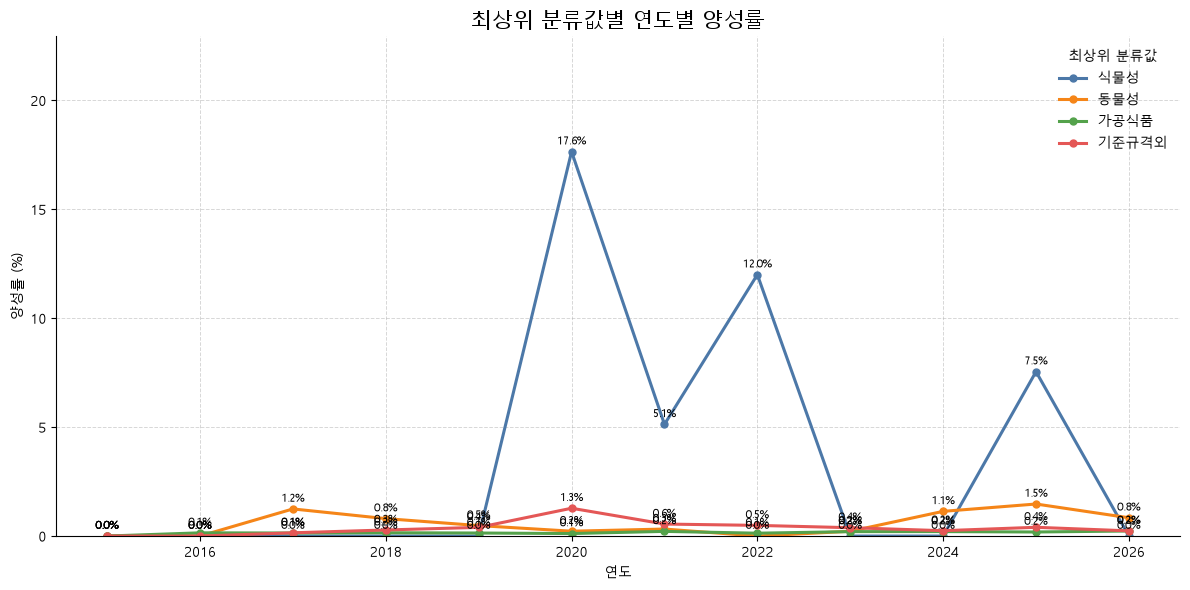

,year,lv1_nm,행수,검출,양성률(%)
0,2015,가공식품,365,0,0.000
1,2016,가공식품,8813,13,0.148
2,2017,가공식품,26648,37,0.139
3,2018,가공식품,25687,39,0.152
4,2019,가공식품,28677,40,0.139
5,2020,가공식품,28720,33,0.115
6,2021,가공식품,27986,60,0.214
7,2022,가공식품,28222,37,0.131
8,2023,가공식품,27132,55,0.203
9,2024,가공식품,26831,55,0.205


In [36]:
# 최상위 분류값(lv1_nm)별 연도별 양성률 시각화
# - 기준: df_joined의 mnfctur_de 기준 연도
# - 지표: 각 분류군 내 검출률 = 검출 / 전체행 * 100

df_year = df_joined.copy()
df_year["year"] = pd.to_datetime(df_year["mnfctur_de"], errors="coerce").dt.year
df_year["is_pos"] = (df_year["judge_result"] == "검출").astype(int)

# 연도 × lv1_nm별 집계
year_lv1 = (
    df_year.groupby(["year", "lv1_nm"], dropna=False)
    .agg(
        행수=("judge_result", "size"),
        검출=("is_pos", "sum")
    )
    .reset_index()
)

year_lv1["양성률(%)"] = (year_lv1["검출"] / year_lv1["행수"] * 100).round(3)

# 각 lv1_nm별 연도별 양성률 피벗
rate_pivot = (
    year_lv1.pivot(index="year", columns="lv1_nm", values="양성률(%)")
    .sort_index()
    .fillna(0)
)

# 실제 데이터가 존재하는 상위 분류 값만 표시
rate_pivot = rate_pivot[[c for c in ["식물성", "동물성", "가공식품", "기준규격외"] if c in rate_pivot.columns]]

# 시각화
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

fig, ax = plt.subplots(figsize=(12, 6))

colors = {
    "식물성": "#4C78A8",
    "동물성": "#F58518",
    "가공식품": "#54A24B",
    "기준규격외": "#E45756",
}

for col in rate_pivot.columns:
    ax.plot(
        rate_pivot.index.astype(int),
        rate_pivot[col].values,
        marker="o",
        linewidth=2.2,
        markersize=5,
        label=col,
        color=colors.get(col, None)
    )

ax.set_title("최상위 분류값별 연도별 양성률", fontsize=15)
ax.set_xlabel("연도")
ax.set_ylabel("양성률 (%)")
ax.grid(True, linestyle="--", linewidth=0.7, alpha=0.5)
ax.set_axisbelow(True)
ax.legend(title="최상위 분류값", frameon=False)
ax.spines[["top", "right"]].set_visible(False)

# y축 범위 보정
ymin = 0
ymax = max(5, rate_pivot.to_numpy().max() * 1.3)
ax.set_ylim(ymin, ymax)

# 값 라벨(간단)
for col in rate_pivot.columns:
    for x, y in zip(rate_pivot.index.astype(int), rate_pivot[col].values):
        if pd.notna(y):
            ax.text(x, y + max(0.2, ymax * 0.01), f"{y:.1f}%", ha="center", va="bottom", fontsize=8)

plt.tight_layout()
plt.show()

# 표 형태도 함께 확인
display(year_lv1.sort_values(["lv1_nm", "year"]).reset_index(drop=True))

#### 식물성이 유의미해보이지만 워낙 적어서 딱히 상관 없는듯. (15행)

### lv1_nm 별 검출 제품명을 보자

In [38]:
# lv1_nm 별 검출 제품명 요약
# - 검출 행만 대상으로
# - 각 상위 분류(lv1_nm)에서 제품명별 검출 건수 집계
# - 상위 N개 제한 없이 전부 표시

pos = df_joined[df_joined["judge_result"] == "검출"].copy()
pos["prduct_nm"] = pos["prduct_nm"].astype(str).fillna("")

# lv1_nm × 제품명별 검출 건수
product_by_lv1 = (
    pos.groupby(["lv1_nm", "prduct_nm"], dropna=False)
       .size()
       .rename("검출건수")
       .reset_index()
       .sort_values(["lv1_nm", "검출건수"], ascending=[True, False])
       .reset_index(drop=True)
)

# lv1_nm별 총 검출 건수
lv1_total = (
    pos.groupby("lv1_nm", dropna=False)
       .size()
       .rename("총검출건수")
       .reset_index()
)

# 표시 행 수 제한 해제 (display 가 중간을 "..." 로 접지 않게)
pd.set_option("display.max_rows", None)
pd.set_option("display.max_colwidth", None)

display(lv1_total.sort_values("총검출건수", ascending=False))
print(f"제품명 종류 수(전체): {len(product_by_lv1):,}")
display(product_by_lv1)

# lv1_nm별로 나눠서 전부 출력
for lv1, df in product_by_lv1.groupby("lv1_nm", sort=True, dropna=False):
    df = df.sort_values("검출건수", ascending=False).reset_index(drop=True)
    print(f"\n=== {lv1} ===  (제품명 {len(df):,}종 / 검출 {df['검출건수'].sum():,}건)")
    display(df)

# 다 본 뒤 원래대로 돌리려면
# pd.reset_option("display.max_rows"); pd.reset_option("display.max_colwidth")


,lv1_nm,총검출건수
1,기준규격외,1431
0,가공식품,449
2,동물성,74
3,식물성,15


제품명 종류 수(전체): 1,623


,lv1_nm,prduct_nm,검출건수
0,가공식품,닭고기염지육,7
1,가공식품,연성치즈,5
2,가공식품,한우목심(냉장),5
3,가공식품,냉장연어살,4
4,가공식품,요니네 한우 한판,4
5,가공식품,춘천닭갈비,4
6,가공식품,한우 목심(냉장),4
7,가공식품,햄,4
8,가공식품,고르곤졸라 돌체,3
9,가공식품,셀덕 오리로스,3



=== 가공식품 ===  (제품명 377종 / 검출 449건)


,lv1_nm,prduct_nm,검출건수
0,가공식품,닭고기염지육,7
1,가공식품,연성치즈,5
2,가공식품,한우목심(냉장),5
3,가공식품,냉장연어살,4
4,가공식품,요니네 한우 한판,4
5,가공식품,춘천닭갈비,4
6,가공식품,한우 목심(냉장),4
7,가공식품,햄,4
8,가공식품,고르곤졸라 돌체,3
9,가공식품,셀덕 오리로스,3



=== 기준규격외 ===  (제품명 1,195종 / 검출 1,431건)


,lv1_nm,prduct_nm,검출건수
0,기준규격외,광어회,10
1,기준규격외,연어회,9
2,기준규격외,ENOKI MUSHROOM GR4-1,6
3,기준규격외,ENOKI MUSHROOM GR4-2,6
4,기준규격외,ENOKI MUSHROOM GR5-3,6
5,기준규격외,수출용 팽이버섯 (2번),6
6,기준규격외,수출용 팽이버섯 (3번),6
7,기준규격외,연어필렛,6
8,기준규격외,ENOKI MUSHROOM GR1-3,5
9,기준규격외,ENOKI MUSHROOM GR4-3,5



=== 동물성 ===  (제품명 42종 / 검출 74건)


,lv1_nm,prduct_nm,검출건수
0,동물성,냉동쇠고기,9
1,동물성,냉동돼지고기,7
2,동물성,냉동다랑어(눈다랑어 필렛횟감),5
3,동물성,"냉동새치(황새치,F,횟감)",4
4,동물성,냉동황새치 필렛횟감,4
5,동물성,"냉동 남방참다랑어 필렛,횟감",3
6,동물성,"참다랑어(냉동,필렛(F),횟감)",3
7,동물성,냉동 눈다랑어 필렛 횟감,2
8,동물성,냉동 황새치 뱃살(횟감),2
9,동물성,냉동다랑어(참다랑어 필렛횟감),2



=== 식물성 ===  (제품명 9종 / 검출 15건)


,lv1_nm,prduct_nm,검출건수
0,식물성,팽이버섯,5
1,식물성,팽이버섯(버섯),3
2,식물성,3-16-1차오름팽이버섯,1
3,식물성,3-16-2솔마을 팽이버섯,1
4,식물성,3-16-5황소고집 팽이버섯,1
5,식물성,갈근,1
6,식물성,갈색팽이버섯,1
7,식물성,밤(탈피),1
8,식물성,사인,1


#### 흠
- 가공식품: 눈으로 봤을때 대부분 육고기(이외엔 수산물) 들어있는 식품임. 원재료에 육고기나 수산물이 들어가있는 지 알 수 있는 자료가 db에 있는지 확인해보자.그 이외에는 냉장' 글자가 있는게 그나마 자주보이는거 같음.
- 기준규격외: 팽이버섯(ENOKI MUSHROOM)이 많아보임. '버섯','MUSHROOM'이 들어가있는 검사는 언제 많이 했는지, 검출이 언제 많이 됐는지, 확인해야할듯. 또 뭘 확인해야하지?
- 동물성: 대부분 육고기, 수산물. 제품명엔 대부분 '냉동'이 들어가있음
- 식물성: 거의 다 팽이버섯임.

#### 결론: 데이터상, 종류무관 육고기,수산물이 들어있는 식품, 팽이버섯(ENOKI MUSHROOM), 냉동 또는 냉장 식품에서 다나옴.
1. 원재료 대부분이 육고기,수산물 여부 칼럼
2. 팽이버섯 여부 칼럼
3. 냉동,냉장 여부 칼럼 
추가하면 잘 맞을듯

### '버섯'·'MUSHROOM' 이 들어간 검사 — 언제 많이 검사했고, 언제 많이 검출됐나 (lv1_nm 별)

In [39]:
# [A] '버섯'·'MUSHROOM' 행 — 규모, 기준일 출처, 연도별 검사 행 수·검출·검출률 (lv1_nm 별)
import re
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

z = df_joined.copy()                                   # 검출 0% 품목 제거본 + t_prdlst_cl 계층(lv1_nm) 전체
z["mnfctur_de"] = pd.to_datetime(z["mnfctur_de"], errors="coerce")
z["pos"] = (z["judge_result"] == "검출").astype(int)
z["year"] = z["mnfctur_de"].dt.year
z["lv1_nm"] = z["lv1_nm"].astype(str)

kw_pat = "|".join(re.escape(k) for k in ["버섯", "MUSHROOM"])
z["is_mush"] = z["prduct_nm"].fillna("").str.contains(kw_pat, case=False, regex=True)
zm = z[z["is_mush"]].copy()                            # 버섯·MUSHROOM 행 전체(lv1_nm 무관). 아래 [B]~[D] 도 이 zm 을 쓴다

n_z, p_z = len(z), int(z["pos"].sum())
n_m, p_m = len(zm), int(zm["pos"].sum())
print(f"df_joined 전체       : {n_z:,}행 / 검출 {p_z:,}건 / 검출률 {p_z / n_z * 100:.3f}%")
print(f"버섯·MUSHROOM 행     : {n_m:,}행 (전체의 {n_m / n_z * 100:.2f}%) / 검출 {p_m:,}건 (전체 검출의 {p_m / p_z * 100:.1f}%) / 검출률 {p_m / n_m * 100:.2f}%")
print(f"버섯 아닌 행         : {n_z - n_m:,}행 / 검출 {p_z - p_m:,}건 / 검출률 {(p_z - p_m) / (n_z - n_m) * 100:.3f}%")

# 1) lv1_nm 별 규모 — 버섯 행 수·검출·검출률, 그 분류 전체에서 버섯이 차지하는 비중, 기준일 출처(date_basis)
lv = zm.groupby("lv1_nm").agg(검사행수=("pos", "size"), 검출=("pos", "sum"))
lv_all = z.groupby("lv1_nm").agg(분류_전체행=("pos", "size"), 분류_전체검출=("pos", "sum"))
lv = lv_all.join(lv, how="left").fillna(0).astype(int)
lv["검출률(%)"] = (lv["검출"] / lv["검사행수"].where(lv["검사행수"] > 0) * 100).round(2)
lv["버섯_행비중(%)"] = (lv["검사행수"] / lv["분류_전체행"] * 100).round(2)                                   # 그 분류 행 중 버섯 비율
lv["버섯_검출비중(%)"] = (lv["검출"] / lv["분류_전체검출"].where(lv["분류_전체검출"] > 0) * 100).round(1)   # 그 분류 검출 중 버섯 비율
basis_all = pd.crosstab(zm["lv1_nm"], zm["date_basis"].astype(str)).add_prefix("기준일_")
basis_pos = pd.crosstab(zm.loc[zm["pos"] == 1, "lv1_nm"], zm.loc[zm["pos"] == 1, "date_basis"].astype(str)).add_prefix("검출행_기준일_")
lv = lv.join(basis_all).join(basis_pos).fillna(0)
basis_cols = [c for c in lv.columns if "기준일_" in c]
lv[basis_cols] = lv[basis_cols].astype(int)
lv = lv.sort_values("검사행수", ascending=False)
lv.index.name = "lv1_nm"
print("\n[1] lv1_nm 별 버섯·MUSHROOM 행 규모와 기준일 출처")
display(lv)

# 2) lv1_nm × 학습용 품목명(train_prdlst_nm): 버섯 행이 어느 코드에 흩어져 있나
by_nm = (zm.groupby(["lv1_nm", zm["train_prdlst_nm"].astype(str)]).agg(검사행수=("pos", "size"), 검출=("pos", "sum")))
by_nm["검출률(%)"] = (by_nm["검출"] / by_nm["검사행수"] * 100).round(2)
print("[2] lv1_nm × train_prdlst_nm 별 버섯 행")
display(by_nm.sort_values("검사행수", ascending=False))

# 3) 연도 × lv1_nm: 검사 행 수 / 검출 / 검출률
yr_n = pd.crosstab(zm["year"], zm["lv1_nm"])
yr_p = pd.crosstab(zm["year"], zm["lv1_nm"], values=zm["pos"], aggfunc="sum").fillna(0).astype(int)
yr_r = (yr_p / yr_n.where(yr_n > 0) * 100).round(2)
yr_lv1 = pd.concat({"검사행수": yr_n, "검출": yr_p, "검출률(%)": yr_r}, axis=1)
yr_lv1.index.name = "연도"
print("[3] 연도 × lv1_nm 별 버섯 행 검사 행 수 / 검출 / 검출률(%)  (검사 0인 칸은 검출률 NaN)")
display(yr_lv1)

# 4) 연도별 합계(lv1_nm 합산) + df_joined 전체 대비 비중 — 아래 [B] 그림이 이 yr 을 쓴다
yr = zm.groupby("year").agg(검사행수=("pos", "size"), 검출=("pos", "sum"))
yr_all = z.groupby("year").agg(전체_검사행수=("pos", "size"), 전체_검출=("pos", "sum"))
yr = yr_all.join(yr, how="left").fillna(0).astype(int)
yr["검출률(%)"] = (yr["검출"] / yr["검사행수"].where(yr["검사행수"] > 0) * 100).round(2)   # 검사 0인 해는 NaN
yr["버섯_검사비중(%)"] = (yr["검사행수"] / yr["전체_검사행수"] * 100).round(2)              # 그 해 전체 검사 중 버섯 비율
yr["버섯_검출비중(%)"] = (yr["검출"] / yr["전체_검출"].where(yr["전체_검출"] > 0) * 100).round(1)  # 그 해 전체 검출 중 버섯 비율
yr = yr[["검사행수", "검출", "검출률(%)", "전체_검사행수", "전체_검출", "버섯_검사비중(%)", "버섯_검출비중(%)"]]
yr.index.name = "연도"
print("[4] 연도별 버섯 행 합계(lv1_nm 합산)와 df_joined 전체 대비 비중")
display(yr)
print("검사 행이 가장 많은 해:", yr["검사행수"].idxmax(), "/ 검출이 가장 많은 해:", yr["검출"].idxmax(),
      "/ 검출률이 가장 높은 해:", yr["검출률(%)"].idxmax())

df_joined 전체       : 600,040행 / 검출 1,969건 / 검출률 0.328%
버섯·MUSHROOM 행     : 8,511행 (전체의 1.42%) / 검출 509건 (전체 검출의 25.9%) / 검출률 5.98%
버섯 아닌 행         : 591,529행 / 검출 1,460건 / 검출률 0.247%

[1] lv1_nm 별 버섯·MUSHROOM 행 규모와 기준일 출처


,분류_전체행,분류_전체검출,검사행수,검출,검출률(%),버섯_행비중(%),버섯_검출비중(%),기준일_선적일,기준일_의뢰일,기준일_제조일,검출행_기준일_의뢰일,검출행_기준일_제조일
lv1_nm,,,,,,,,,,,,
기준규격외,320464,1431,8112,497,6.13,2.53,34.7,0,4988,3124,343,154
가공식품,268945,449,316,0,0.00,0.12,0.0,7,65,244,0,0
식물성,427,15,83,12,14.46,19.44,80.0,0,82,1,12,0
동물성,10204,74,0,0,0.00,0.00,0.0,0,0,0,0,0


[2] lv1_nm × train_prdlst_nm 별 버섯 행


검사행수   검출  검출률(%)
lv1_nm train_prdlst_nm                   
기준규격외  정액,수정란,종란        6294  486    7.72
       기타기준규격외          1818   11    0.61
가공식품   즉석식품류             175    0    0.00
식물성    버섯류                83   12   14.46
가공식품   식육가공품 및 포장육        79    0    0.00
       기타식품류              31    0    0.00
       농산가공식품류            12    0    0.00
       음료류                11    0    0.00
       유가공품류               8    0    0.00

[3] 연도 × lv1_nm 별 버섯 행 검사 행 수 / 검출 / 검출률(%)  (검사 0인 칸은 검출률 NaN)


검사행수             검출           검출률(%)              
lv1_nm 가공식품 기준규격외 식물성 가공식품 기준규격외 식물성   가공식품  기준규격외    식물성
연도                                                       
2016      4     0   0    0     0   0    0.0    NaN    NaN
2017     34    47   1    0     0   0    0.0   0.00   0.00
2018     32   121   0    0     0   0    0.0   0.00    NaN
2019     33   119   5    0     1   0    0.0   0.84   0.00
2020     33  2332   7    0   280   3    0.0  12.01  42.86
2021     33   958   0    0    48   0    0.0   5.01    NaN
2022     38  1706  35    0    77   5    0.0   4.51  14.29
2023     54  1083   0    0    53   0    0.0   4.89    NaN
2024     28   735   0    0    17   0    0.0   2.31    NaN
2025     18   646  35    0    19   4    0.0   2.94  11.43
2026      9   365   0    0     2   0    0.0   0.55    NaN

[4] 연도별 버섯 행 합계(lv1_nm 합산)와 df_joined 전체 대비 비중


,검사행수,검출,검출률(%),전체_검사행수,전체_검출,버섯_검사비중(%),버섯_검출비중(%)
연도,,,,,,,
2015,0,0,NaN,382,0,0.00,NaN
2016,4,0,0.00,9554,13,0.04,0.0
2017,82,0,0.00,39089,67,0.21,0.0
2018,153,0,0.00,46549,103,0.33,0.0
2019,157,1,0.64,52042,133,0.30,0.8
2020,2372,283,11.93,57665,396,4.11,71.5
2021,991,48,4.84,62027,248,1.60,19.4
2022,1779,82,4.61,64852,219,2.74,37.4
2023,1137,53,4.66,69280,215,1.64,24.7


검사 행이 가장 많은 해: 2020 / 검출이 가장 많은 해: 2020 / 검출률이 가장 높은 해: 2020


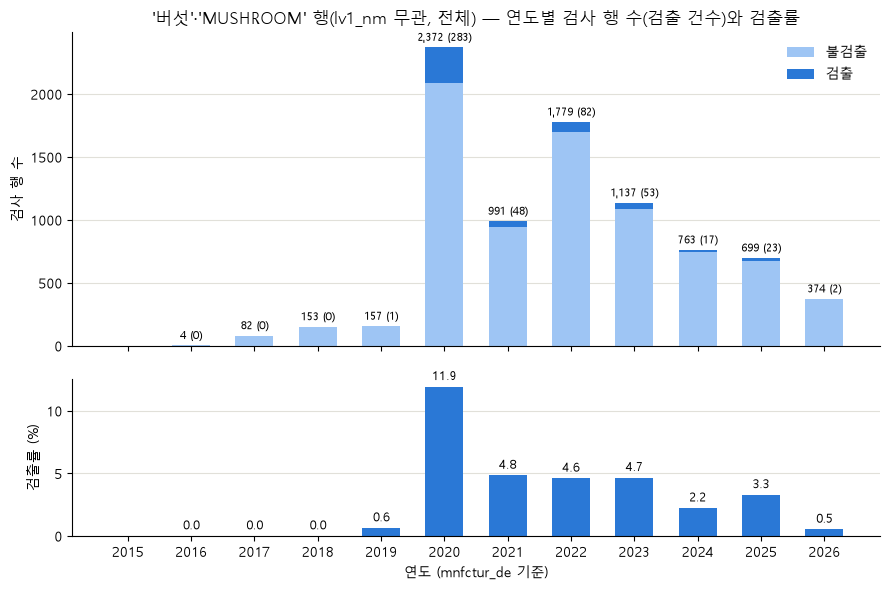

In [40]:
# [B] 연도별 그림 — 위: 버섯 행 검사 수(불검출/검출 누적), 아래: 검출률
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
x = yr.index.astype(str)
불검출 = yr["검사행수"] - yr["검출"]

ax1.bar(x, 불검출, color="#9ec5f4", width=0.6, label="불검출")
ax1.bar(x, yr["검출"], bottom=불검출, color="#2a78d6", width=0.6, label="검출")
ax1.bar_label(ax1.containers[1],
              labels=[f"{n:,} ({p})" if n else "" for n, p in zip(yr["검사행수"], yr["검출"])],
              padding=3, fontsize=8)
ax1.set_ylabel("검사 행 수")
ax1.set_title("'버섯'·'MUSHROOM' 행(lv1_nm 무관, 전체) — 연도별 검사 행 수(검출 건수)와 검출률")
ax1.legend(frameon=False)

ax2.bar(x, yr["검출률(%)"].fillna(0), color="#2a78d6", width=0.6)
ax2.bar_label(ax2.containers[0],
              labels=[f"{v:.1f}" if n else "" for v, n in zip(yr["검출률(%)"].fillna(0), yr["검사행수"])],
              padding=3, fontsize=9)
ax2.set_ylabel("검출률 (%)")
ax2.set_xlabel("연도 (mnfctur_de 기준)")

for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
    ax.yaxis.grid(True, color="#e1e0d9", linewidth=0.8)
    ax.set_axisbelow(True)
plt.tight_layout()
# fig.savefig(r"C:\Users\NT751\Desktop\천영진\리스테리아ML\docs\00_보고서\fig_버섯_연도별.png", dpi=150)
plt.show()

기간: 2016-08 ~ 2026-06 (119개월, 검사 있는 달 118개월)

검사 행이 많은 달 TOP 10


,검사행수,검출,검출률(%)
연월,,,
2020-12,599,135,22.54
2020-08,534,21,3.93
2020-11,409,91,22.25
2023-07,344,3,0.87
2022-07,262,11,4.20
2021-12,251,7,2.79
2020-05,214,4,1.87
2022-08,214,30,14.02
2022-03,205,2,0.98


검출이 많은 달 TOP 10


,검사행수,검출,검출률(%)
연월,,,
2020-12,599,135,22.54
2020-11,409,91,22.25
2021-01,165,31,18.79
2022-08,214,30,14.02
2020-08,534,21,3.93
2022-09,151,18,11.92
2023-10,88,17,19.32
2023-09,100,16,16.00
2023-08,134,12,8.96


검출 상위 5개월 합계: 308건 = 버섯 검출 509건의 60.5%  → 2020-12, 2020-11, 2021-01, 2022-08, 2020-08


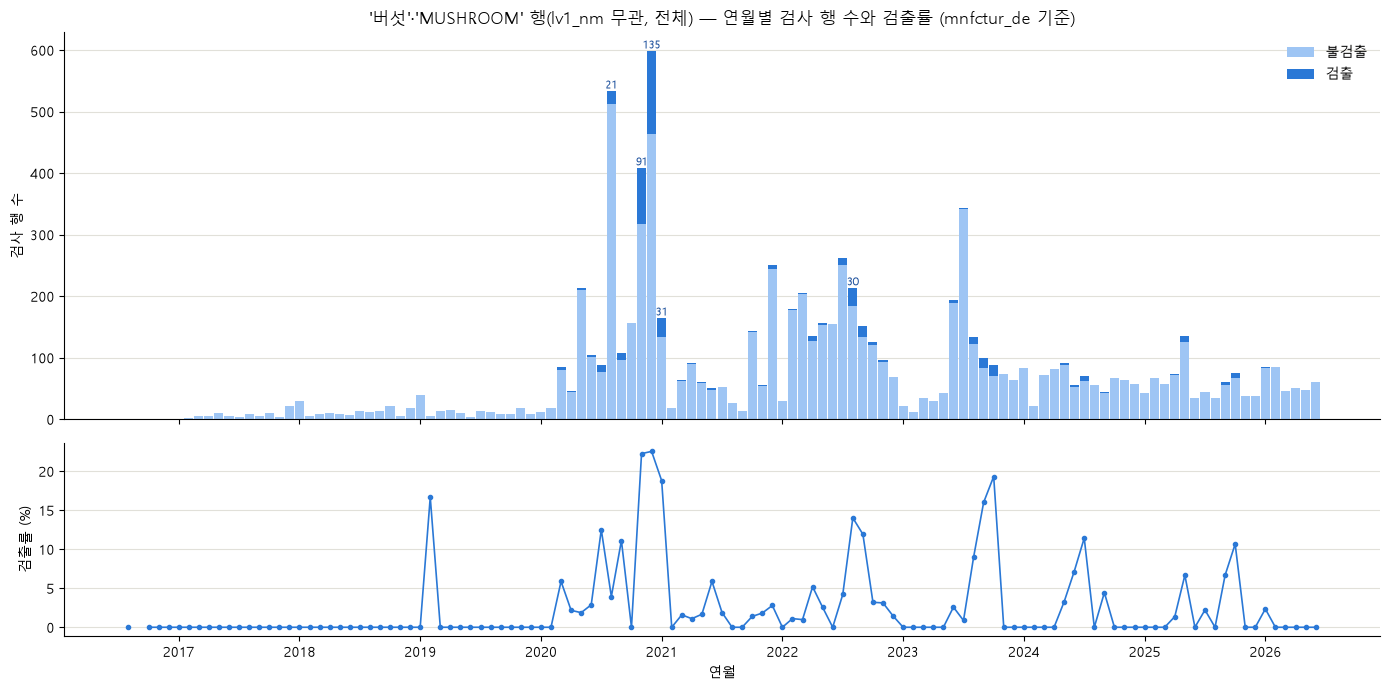

In [41]:
# [C] 연월별(YYYY-MM) — 검사가 몰린 달과 검출이 몰린 달을 따로 본다
zm["ym"] = zm["mnfctur_de"].dt.to_period("M")
ym = zm.groupby("ym").agg(검사행수=("pos", "size"), 검출=("pos", "sum"))
ym = ym.reindex(pd.period_range(ym.index.min(), ym.index.max(), freq="M"), fill_value=0)   # 검사가 없던 달은 0
ym["검출률(%)"] = (ym["검출"] / ym["검사행수"].where(ym["검사행수"] > 0) * 100).round(2)   # 검사 없는 달은 NaN
ym.index.name = "연월"

print(f"기간: {ym.index.min()} ~ {ym.index.max()} ({len(ym)}개월, 검사 있는 달 {(ym['검사행수'] > 0).sum()}개월)")
print("\n검사 행이 많은 달 TOP 10")
display(ym.sort_values("검사행수", ascending=False).head(10))
print("검출이 많은 달 TOP 10")
display(ym.sort_values(["검출", "검사행수"], ascending=False).head(10))

top_det = ym.sort_values("검출", ascending=False).head(5)
print(f"검출 상위 5개월 합계: {int(top_det['검출'].sum()):,}건 = 버섯 검출 {int(ym['검출'].sum()):,}건의 "
      f"{top_det['검출'].sum() / ym['검출'].sum() * 100:.1f}%  → {', '.join(str(i) for i in top_det.index)}")

# 그림: 위 = 월별 검사 행 수(불검출/검출 누적), 아래 = 월별 검출률 (검사 없는 달은 비움)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
xs = range(len(ym))
불검출 = ym["검사행수"] - ym["검출"]
ax1.bar(xs, 불검출, color="#9ec5f4", width=0.9, label="불검출")
ax1.bar(xs, ym["검출"], bottom=불검출, color="#2a78d6", width=0.9, label="검출")
ax1.set_ylabel("검사 행 수")
ax1.set_title("'버섯'·'MUSHROOM' 행(lv1_nm 무관, 전체) — 연월별 검사 행 수와 검출률 (mnfctur_de 기준)")
ax1.legend(frameon=False)
for i, (n, p) in enumerate(zip(ym["검사행수"], ym["검출"])):
    if p >= 20:                                   # 검출 20건 이상인 달만 숫자 표시
        ax1.text(i, n, f"{p}", ha="center", va="bottom", fontsize=8, color="#1b4f9c")

ax2.plot(xs, ym["검출률(%)"], color="#2a78d6", marker="o", markersize=3, linewidth=1.2)
ax2.set_ylabel("검출률 (%)")
ax2.set_xlabel("연월")

tick_pos = [i for i, p in enumerate(ym.index) if p.month == 1]
ax2.set_xticks(tick_pos)
ax2.set_xticklabels([str(ym.index[i].year) for i in tick_pos])
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
    ax.yaxis.grid(True, color="#e1e0d9", linewidth=0.8)
    ax.set_axisbelow(True)
plt.tight_layout()
# fig.savefig(r"C:\Users\NT751\Desktop\천영진\리스테리아ML\docs\00_보고서\fig_버섯_연월별.png", dpi=150)
plt.show()

전체             2020년 제외           
    검사행수   검출 검출률(%)     검사행수  검출 검출률(%)
월                                       
1    508   33   6.50      497  33   6.64
2    415    3   0.72      397   3   0.76
3    591    8   1.35      506   3   0.59
4    535   10   1.87      489   9   1.84
5    776   21   2.71      562  17   3.02
6    671   15   2.24      567  12   2.12
7    893   35   3.92      805  24   2.98
8   1029   63   6.12      495  42   8.48
9    504   52  10.32      396  40  10.10
10   697   31   4.45      541  31   5.73
11   762   95  12.47      353   4   1.13
12  1130  143  12.65      531   8   1.51

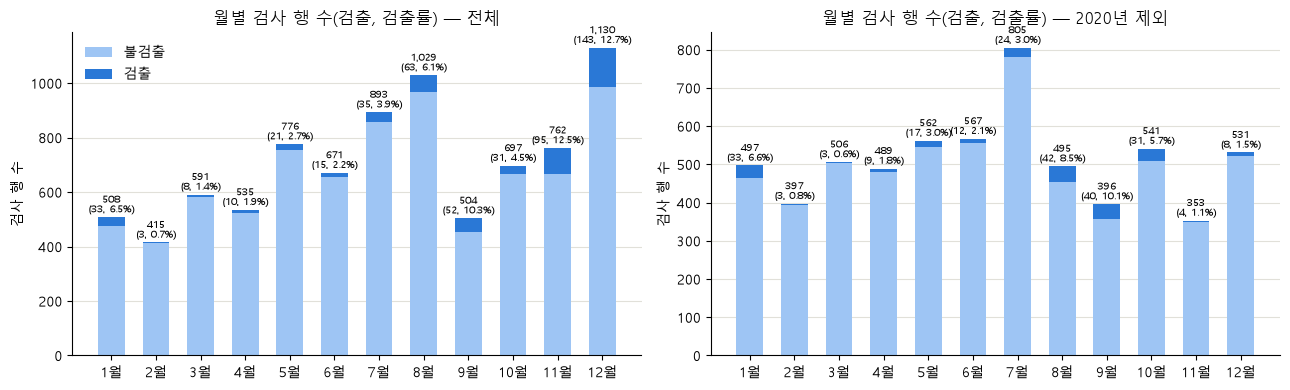

In [42]:
# [D] 월(1~12월) 합산 — 계절처럼 보이는지, 특정 해(2020) 때문인지 구분하려고 전체와 2020년 제외를 나란히 둔다
zm["month"] = zm["mnfctur_de"].dt.month

def month_tbl(d):
    t = d.groupby("month").agg(검사행수=("pos", "size"), 검출=("pos", "sum")).reindex(range(1, 13), fill_value=0)
    t["검출률(%)"] = (t["검출"] / t["검사행수"].where(t["검사행수"] > 0) * 100).round(2)
    return t

mo_all = month_tbl(zm)
mo_ex2020 = month_tbl(zm[zm["year"] != 2020])
mo = pd.concat({"전체": mo_all, "2020년 제외": mo_ex2020}, axis=1)
mo.index.name = "월"
display(mo)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=False)
for ax, (name, t) in zip(axes, [("전체", mo_all), ("2020년 제외", mo_ex2020)]):
    xm = [f"{m}월" for m in t.index]
    불검출 = t["검사행수"] - t["검출"]
    ax.bar(xm, 불검출, color="#9ec5f4", width=0.6, label="불검출")
    ax.bar(xm, t["검출"], bottom=불검출, color="#2a78d6", width=0.6, label="검출")
    ax.bar_label(ax.containers[1],
                 labels=[f"{n:,}\n({p}, {r:.1f}%)" if n else "" for n, p, r in zip(t["검사행수"], t["검출"], t["검출률(%)"].fillna(0))],
                 padding=2, fontsize=7)
    ax.set_title(f"월별 검사 행 수(검출, 검출률) — {name}")
    ax.set_ylabel("검사 행 수")
    ax.spines[["top", "right"]].set_visible(False)
    ax.yaxis.grid(True, color="#e1e0d9", linewidth=0.8)
    ax.set_axisbelow(True)
axes[0].legend(frameon=False)
plt.tight_layout()
# fig.savefig(r"C:\Users\NT751\Desktop\천영진\리스테리아ML\docs\00_보고서\fig_버섯_월별.png", dpi=150)
plt.show()

#### 인사이트
1. 가공된 버섯에선 안나오는듯. 원물 팽이버섯에서 많이 나오는듯 
- 가공식품에서 0건, 기준규격외 또는 식물성. 거의 기준규격외
2. '팽이버섯 여부' 칼럼은 신호가 확실함
- 버섯은 행의 1.4%(8,511행)인데 검출의 26%(509건). 검출률 5.98% 로 버섯 아닌 행(0.25%)의 24배
- 대신 시점 편향이 큼. 검출 509건 중 2020년 283건(56%), 그중 2020-11·12 두 달이 226건(44%). 2020년 검사 2,372행은 다른 해의 1.3~3배 → 2020년 집중검사 하나가 만든 신호에 가까움
- 2021년 이후 검출률 2~5%, 2026 상반기 0.5%. test(2025-07~2026-06)에선 "팽이버섯 = 고위험" 규칙이 과대예측할 위험 → 2020년 행을 학습에서 어떻게 다룰지(그대로/가중치/제외/실험 후 결정) 정해야 함
- 11~12월 검출률 봉우리(12~13%)는 계절 아님. 2020년 빼면 1%대로 사라짐. 2020년 빼고 남는 건 8~9월(8.5·10.1%)과 1월(6.6%) → 월·기상 변수 효과는 2020년 제외하고 판단
- 버섯 행 8,511 중 기준일(mnfctur_de)이 의뢰일 5,135(60.3%)·제조일 3,369(39.6%)·선적일 7(0.1%, 가공식품만). 검출 509건은 의뢰일 355(69.7%)·제조일 154(30.3%) → 위 시점은 "언제 만들었나"보다 "언제 검사했나"에 가까움. 제조일 기준 기상 lookback 이 이 행들에선 사실상 검사일 기준이 됨 (팽이버섯은 실내재배라 기상 가설 자체가 약함)
3. 품목 코드가 아니라 제품명 키워드로 '팽이버섯 여부' 칼럼을 만드는 게 맞을듯.
- 같은 팽이버섯이 Z27(정액,수정란,종란)·Z38(기타기준규격외)·A07(버섯류) 세 코드에 흩어짐 →  식물성 '버섯류' 검출률 14.5%(83행·12건)는 행이 적어 참고만

# 중간정리

(2026-09-22 작성. 1~6절 결과를 바탕으로 "어떤 변수를 만들 것인가"를 정리한 것. **결정이 아니라 후보**이며, 채택 여부는 사용자·교수님 확인 뒤 `docs/00_보고서/작업기록.md` 에 남긴다.)

## 1. 지금까지 확인한 사실 (변수 후보의 근거)

데이터 흐름: `data/listeria_body.parquet` 676,537행(검출 1,969건, 0.291%) → 검출 0% 인 학습용 품목명(`train_prdlst_nm`) 38개 제거 → `df_filtered` 600,040행(검출 1,969건, 0.328%) → `ba_data.t_prdlst_cl`(식품공전 품목분류 계층표)을 `train_prdlst_code` 로 조인 → `df_joined`(`lv1_cd`~`lv6_nm` 파생 열, 매칭 100%).

| # | 확인한 사실 | 수치 (`df_filtered` / `df_joined` 기준) | 절 |
|---|---|---|---|
| 1 | 검출의 89%가 학습용 품목명 3개에 몰림 | 기타기준규격외 791 · 정액,수정란,종란 640 · 식육가공품 및 포장육 323 = 1,754 / 1,969 | 4 |
| 2 | 제품명에 '버섯'·'MUSHROOM' 이 든 행은 행의 1.4%인데 검출의 26% | 8,511행 / 검출 509건 / 검출률 5.98% (버섯 아닌 행 0.247% 의 24배) | 6 [A] |
| 3 | 버섯 검출은 2020년에 몰림 → 시점 편향 | 2020년 283건(56%), 2020-11·12 두 달 226건. 검사기관 `inspct_instt_code` = O000084 한 곳이 479건. 2021년 이후 검출률 2~5%, 2026년 상반기 0.5% | 4, 6 [C] |
| 4 | 같은 팽이버섯이 품목 코드 3개에 흩어짐 | Z27 정액,수정란,종란 6,294행·검출 486 / Z38 기타기준규격외 1,818·11 / A07 버섯류 83·12. 가공식품(C) 버섯 316행은 검출 0 | 6 [A] 표[2] |
| 5 | 최상위 분류(`lv1_nm`)별 검출률 | 기준규격외 0.447%(1,431건, 검출의 72.7%) · 가공식품 0.167%(449건) · 동물성 0.725%(74건) · 식물성 3.513%(15건) | 6 |
| 6 | 가공식품(C) 검출은 육가공·연질치즈·연어에 집중 | 닭고기염지육 7, 한우목심(냉장) 5+4, 연성치즈 5, 고르곤졸라 3+2+2, 햄 4, 냉장연어살 4, 생햄·잠봉·하몽 각 2 | 6 검출 제품명 |
| 7 | 동물성(B) 검출은 냉동 육류·냉동 다랑어 횟감 | 냉동쇠고기 9, 냉동돼지고기 7, 상위 11개 제품명 중 9개가 '냉동 … 필렛 횟감' | 6 검출 제품명 |
| 8 | 기준규격외(Z) 검출은 회·초밥·포장육·팽이버섯·공정 시료 | 광어회 10, 연어회 9, 연어필렛 6, 포장육 완제품 5. 제품명에 '가열전/가열후·완제품·원료육·세척전·CCP 전/후·환경검체' 같은 공정 단계 표기가 많음 | 4, 5 |
| 9 | 기준일 `mnfctur_de` 의 출처가 섞여 있음 | `date_basis` 의뢰일 315,078 · 제조일 241,764 · 선적일 43,198. 버섯 검출 509건 중 70%는 의뢰일 기준 | 3, 6 |
| 10 | 연도별 양성률 추세가 분류마다 다름 | 기준규격외 2020년 1.28% 봉우리 뒤 0.24~0.55%, 가공식품 0.12~0.23% 로 평탄, 동물성 2024~2025년 1.1~1.5% 로 상승 | 6 연도별 |

## 2. 만들 변수 후보

우선순위: ★★★ 먼저 만든다 / ★★ 만들되 효과·누수 검증 / ★ 자료 확보 뒤

### 2-1. 제품명(`prduct_nm`) 키워드 변수 — 품목 코드가 못 잡는 정보 (★★★)

근거: 사실 2·4·6·7·8. 품목 코드는 15개뿐이고 팽이버섯이 코드 3개에 흩어지며, 검출 제품명에 위험식품(육류·수산·연질치즈)·보관 상태(냉장·냉동)·공정 단계가 글자로 들어 있다. `prduct_nm` 결측 1행이라 사실상 모든 행에 만들 수 있다. 규칙은 "아래 낱말 중 하나라도 포함(대소문자 무시)".

| 변수(안) | 낱말 | 근거 |
|---|---|---|
| `kw_enoki` 팽이버섯 여부 | 팽이 · ENOKI | 사실 2~4. 사용자 결론 2번 |
| `kw_mushroom_other` 팽이 아닌 버섯 | (버섯 · MUSHROOM) 이면서 팽이·ENOKI 아님 | 느타리·새송이·표고와 팽이의 검출률이 다른지 확인용 |
| `kw_meat` 육류 | 소 · 한우 · 우육 · 돼지 · 한돈 · 돈육 · 닭 · 계육 · 오리 · 양고기 · 정육 · 포장육 · 원료육 · 목심 · 등심 · 안심 · 갈비 · 족발 · 햄 · 소시지 · 소세지 · 베이컨 · 잠봉 · 하몽 · 생햄 · 육포 · 불고기 · 염지 | 사실 6·7. 사용자 결론 1번 |
| `kw_seafood` 수산물 | 연어 · 광어 · 참치 · 다랑어 · 황새치 · 새치 · 횟감 · 회 · 필렛 · 새우 · 가리비 · 문어 · 오징어 · 굴 · 조개 · 어묵 · 명란 · 젓갈 | 사실 7·8. '회'·'굴'은 한 글자라 오탐(예: 회사, 굴소스) 확인 필요 |
| `kw_cheese_soft` 연질·자연치즈 | 연성치즈 · 자연치즈 · 고르곤졸라 · 탈레지오 · 브리 · 카망베르 · 모짜렐라 · 리코타 · 생치즈 | 사실 6. `docs/01_메모/info.md` 6번 위험식품 |
| `kw_rte` 즉석섭취 | 김밥 · 도시락 · 초밥 · 샐러드 · 샌드위치 · 덮밥 | 전체 상위 제품명(도시락 1,183·김밥 1,131·광어초밥). info.md 10번 "그대로 섭취 여부" |
| `kw_frozen` / `kw_chilled` | 냉동 / 냉장 | 사실 7. 사용자 결론 3번. 냉장은 증식, 냉동은 생존만(info.md 11·12번) |
| `kw_stage` 공정 단계(범주) | '가열 전' = 가열전 · 살균전 · 세척전 · 원료 · 입고 · 반제품 / '가열 후·완제품' = 가열후 · 살균후 · 완제품 · 출고 / '환경' = 환경검체 · 쿨러 · 가습기 · 배수구 · 도마 · 작업대 · 장갑 / 나머지 '표기 없음' | 사실 8. 가열 후 양성 = 공정환경 오염(info.md 9번) |
| `kw_export` 수출용 | 수출용 · EXPORT | Z27 팽이버섯이 수출 검사(검사기관 O000084) |
| `kw_none` 키워드 없음 | 위 규칙에 하나도 안 걸림 | "키워드 없음" 행의 검출률이 규칙의 빈틈을 보여줌 |

주의: 낱말 목록을 **검출 제품명을 보고** 고르면 test 기간(2025-07~2026-06) 정보가 섞인다. 목록은 `info.md` 위험식품 + 학습 기간(2024-06-30 이전) 검출 제품명만 보고 정하고, 그 근거를 작업기록에 남긴다.

### 2-2. 품목 계층 변수 — 이미 만든 것 정리 (★★★)

| 변수 | 내용 | 비고 |
|---|---|---|
| `lv1_cd` | A 식물성 / B 동물성 / C 가공식품 / Z 기준규격외 (4값) | 6절 조인 결과 |
| `train_prdlst_code` | 학습용 품목 코드 15개 | 범주형 그대로. 타깃 인코딩·빈도 통계는 fold 안에서 계산 |
| `is_processed` | `train_prdlst_code` 가 C 로 시작 | 5절. `lv1_cd == 'C'` 와 600,040행 전부 같음 |
| (후보) 원본 `prdlst_code` 앞 14자리 → `ba_data.t_prdlst_cl` 3~4단계 | DB 몸통 `ready_data.hazard_preprocessed_data` 의 `statistic_prdlst_nm_3`(154종)·`_4`(431종) 수준 | 15개보다 잘게 나뉨. test 에만 있는 코드는 상위 단계로 되돌리는 규칙 필요(작업기록 09-21: 미등장 코드 행 0.16%, 검출 0) |

### 2-3. 시간·기준일 변수 (★★★)

| 변수 | 내용 | 비고 |
|---|---|---|
| `month` (또는 sin·cos) | `mnfctur_de` 의 월 | 계절 베이스라인. 단 버섯 11~12월 봉우리는 2020년 효과라 계절이 아님(6절 [D]) |
| `date_basis` | 제조일 / 의뢰일 / 선적일 | 사실 9. 기준일의 뜻이 다르므로 기상 lookback 해석도 달라짐 |
| `has_mnfctur_de` | 원본 제조일 존재 여부 | 결측 여부 플래그 실험. 검출과 상관이 있으면 누수인지 먼저 판단 |
| `year` | 연도 | **넣지 않는 쪽 권고** — test 연도는 학습에 없는 값이라 외삽. 추세는 후향 검증에서 확인 |

### 2-4. 검사·출처 맥락 변수 (★★ — 포함 여부 결정 필요)

| 변수 | 근거 | 걱정 |
|---|---|---|
| `src_route` 국내/해외, `addr_source` | 3절 요약 | 없음 |
| `inspct_instt_code` 검사기관(254종) | 버섯 검출 509건 중 479건이 O000084. 기관 = 검사 목적(수출·자체의뢰)의 대리 변수 | "누가 검사했나"가 예측 시점에 아는 정보인지, 일반화되는지 결정 필요. 쓰면 fold 안 타깃 인코딩 |
| 검사목적 `inspct_purps_code` (`ba_data.m_org_lims_data_info`, parquet 에 없음) | 검출 1,969건 중 '기타'(자체의뢰) 82%(작업기록 09-14) | DB 조인 필요. 위와 같은 걱정 |
| 제조사 `mnfctur_cmpny_nm` 과거 검출 이력 | 반복 시료 많음((주)청미 2,467행 등) | 결측 52%. 기준일 **이전** 행만으로 계산해야 누수 없음(확장 창) |
| 지역 `legal_dong_code` 앞 2·5자리(시도·시군구) | 결측 7.3%(해외 행) | 4.ipynb: 시도 보정 뒤 기온 신호 약해짐 → 기상과 상관 있음 |

### 2-5. 외부 데이터 (★★ — 붙인 뒤 베이스라인과 비교)

- 기상(`api_data_info.kma_asos_daily_info`·`nas_agri_weather_daily_info`, 해외 `global_factory_weather`): D-1~D-100 을 다 펼치지 말고 **구간 집계**(D-1~7 / D-1~30 / D-1~100 의 평균·최대·임계 초과 일수)부터. D0 포함 여부를 먼저 정해 고정.
- 붙일 대상: info.md 13번대로 "국내 × 원물·최소가공 × 제조일 기준" 행에 먼저. 팽이버섯은 실내재배라 기상 가설이 약하고, 의뢰일 기준 행은 "검사 전 날씨"가 됨 → `date_basis`·`is_processed`·`kw_*` 와의 교호작용으로 본다.
- 관측소는 시료 파일 `lat`·`lon` 기준 가까운 3곳(부족하면 5곳) 평균, 직선거리.
- 품목 속성: 수분활성도·pH·염도 `ba_data.t_aw_cl`(`prdlst_cd` 14자리로 연결, `aw`·`ph`·`na`·`mc`) — 리스테리아 증식 한계와 직접 관련. 토양 `soil_ph_info` 는 매일 자료가 아니라 결합 방법 별도(작업기록 09-21).

### 2-6. 품목제조대장 `ba_data.t_prdlst_mnf_ledg` — 7절에서 탐색할 것 (★)

정의서 37컬럼 중 후보: `pog_daycnt`(유통기한 문구 → 일수로 파싱), `frmlc_mtrqlt`(포장 재질 — '진공' 여부), `mnf_cnd_cn`(제조 조건 내용 — 살균·가열 조건이 들어 있는지), `prsrv_distb_stdr_cn`(보존·유통 기준 — 냉장/냉동/실온, 거의 비어 있음), `etqty_xport_prdlst_yn`(전량 수출 여부), `haccp_appn_no`(전체 NULL 로 확인됨).
주의: 국내 행 1/3 만 연결되고 **검출 행은 11%만 연결**(작업기록 09-14) → 값보다 "연결 여부"가 검출과 상관이 생겨 누수·편향 위험. 검출/불검출 연결률 차이를 먼저 보고 쓸지 정한다.
원재료: 사용자 결론 1번(원재료 육류·수산물 여부)은 `ba_data_info.lcns_ledg_hist_rawmtrl`(원료명·원산지·배합비, 5,148만 행, 정의서에 없는 스키마, 모델팀 질문 중)로 만들 수 있으나 무겁다 → 1차는 제품명 키워드(2-1)로, 2차에 대장 원재료로 보강.

## 3. 변수 만들기 전에 정해야 할 것 (사용자·교수님)

1. **검출 0% 품목 38개 제거**(2절)는 전 기간(test 포함) 타깃을 보고 정한 것 → 학습 기간(~2024-06-30)만으로 판정해도 같은 38개인지 확인하고, 승인 사실을 작업기록에 남긴다.
2. **가공식품(C) 제외 여부**(5절 "가공식품 제외해도 될듯?") — 제외하면 검출 449건(22.8%)·행 268,945 를 잃고, 그 검출이 교과서적 위험식품(육가공·연질치즈·연어)이다. 제외 대신 `is_processed` 를 넣고 두거나 분리 모델로 비교하는 쪽을 권고(추정 — 성능으로 확인 필요).
3. **2020년 버섯 집중검사 행**(검출 283건) — 그대로 / 가중치 / 제외. test 기간 버섯 검출률 0.5~3% 라 "팽이버섯 = 고위험" 규칙이 과대예측할 위험(6절 인사이트).
4. **몸통 재추출 여부** — parquet(09-08) 의 `train_prdlst_code` 가 현재 DB 와 9,236행 다름(작업기록 09-22). 재추출하면 유가공품류 4,079행이 빙과류(0% 품목)로 빠지는 등 15개 품목 구성이 바뀜.
5. 검사기관·검사목적 변수를 넣을지(2-4), 기상 D0 포함 여부(2-5).

## 4. 다음에 할 분석 (우선순위 순)

1. 0% 품목 제거의 시간 안정성 — 학습 기간만으로 0% 인 품목 목록과 비교, 제거된 38개 품목의 test 기간 행 수.
2. 키워드 변수 프로토타입 — 2-1 규칙별 행수·검출·검출률·연도 분포·`lv1_nm` 분포, 키워드 없음 행의 검출률, 팽이 vs 다른 버섯, 냉장 vs 냉동, 공정 단계별 검출률.
3. 기준규격외(Z38·Z27) 검출 1,431건 중 버섯 아닌 934건의 정체 — 공정 단계 낱말 × 검출률, 검사목적(`ba_data.m_org_lims_data_info.inspct_purps_code`) 조인.
4. 반복 시료 구조 — 제조사·검사기관별 행수·검출 집중도(상위 10곳의 검출 비중), 같은 제조사가 train 과 test 에 걸치는 비율.
5. 시간 순 분할 점검(`df_filtered` 기준) — 확장 창 fold 별 양성 수, test 기간 검출 구성(작업기록 09-21: 기타기준규격외 59%, 버섯 16%).
6. 베이스라인 3개 — 품목만(`train_prdlst_code`), 월만, (기상 붙인 뒤) 기상만. PR 곡선·임계값 스윕, recall 우선.
7. 기상 결합 대상 규모 — 국내 × 원물·최소가공 × 제조일 기준 행 수·검출 수(붙여서 의미 있는 행이 얼마인지).
8. 7절 품목제조대장 — 검출/불검출 연결률 차이, `pog_daycnt`·`frmlc_mtrqlt`·`mnf_cnd_cn` 채움률.
9. `date_basis`·원본 제조일 존재 여부별 검출률 — 결측 플래그가 신호인지 누수인지.
10. 수입(overseas) 43,774행 따로 — 검출 구성(냉동 다랑어 횟감·치즈), 국가별.

# 7. 해외 vs 국내

In [46]:
import numpy as np

In [53]:
# 국내/해외 × 최상위 분류(lv1_nm) — 검출 수와 전체 검출 중 비율
pos = df_joined[df_joined["judge_result"] == "검출"]
pos_all = len(pos)

t = (pos.assign(경로=pos["src_route"].map({"domestic": "국내", "overseas": "해외"}))
        .groupby(["경로", "lv1_nm"]).size()
        .reindex(pd.MultiIndex.from_product([["국내", "해외"], ["식물성", "동물성", "가공식품", "기준규격외"]],
                                            names=["경로", "lv1_nm"]), fill_value=0)
        .rename("검출").to_frame())
t["비율(%)"] = (t["검출"] / pos_all * 100).round(2)

print(f"전체 검출 {pos_all:,}건")
display(t)

전체 검출 1,969건


검출  비율(%)
경로 lv1_nm             
국내 식물성       15   0.76
   동물성       12   0.61
   가공식품     386  19.60
   기준규격외   1431  72.68
해외 식물성        0   0.00
   동물성       62   3.15
   가공식품      63   3.20
   기준규격외      0   0.00

In [52]:
# 국내/해외 × 최상위 분류(lv1_nm) — 검출 수와 전체 검출 중 비율 (검출 수 내림차순)
pos = df_joined[df_joined["judge_result"] == "검출"]
pos_all = len(pos)

t = (pos.assign(경로=pos["src_route"].map({"domestic": "국내", "overseas": "해외"}))
        .groupby(["경로", "lv1_nm"]).size()
        .reindex(pd.MultiIndex.from_product([["국내", "해외"], ["식물성", "동물성", "가공식품", "기준규격외"]],
                                            names=["경로", "lv1_nm"]), fill_value=0)
        .rename("검출").to_frame())
t["비율(%)"] = (t["검출"] / pos_all * 100).round(2)
t = t.sort_values("검출", ascending=False)

print(f"전체 검출 {pos_all:,}건")
display(t)


전체 검출 1,969건


검출  비율(%)
경로 lv1_nm             
국내 기준규격외   1431  72.68
   가공식품     386  19.60
해외 가공식품      63   3.20
   동물성       62   3.15
국내 식물성       15   0.76
   동물성       12   0.61
해외 식물성        0   0.00
   기준규격외      0   0.00

In [51]:
# 타겟 judge_result 의 유니크 값별 건수와 비율 (결측 포함)
_vc = df_joined['judge_result'].value_counts(dropna=False)
df_타겟분포 = pd.DataFrame({
    'judge_result': _vc.index.astype(object),
    '건수': _vc.values,
    '비율(%)': (_vc.values / len(df_joined) * 100).round(3),
})
df_타겟분포.loc[len(df_타겟분포)] = ['합계', len(df_joined), 100.0]

display(df_타겟분포)

,judge_result,건수,비율(%)
0,불검출,598071,99.672
1,검출,1969,0.328
2,합계,600040,100.000


# N. 't_prdlst_mnf_ledg' 테이블(또는 그 이외)에서 쓸만한 제조 공정 데이터 탐색 및 조인